# Comparative Analysis: Trial Length & Flexibility Across Experimental Setups

This notebook extracts, processes, and plots training dynamics across multiple experimental setups from **Weights & Biases (W&B)** and local cache files:
1. **Experimental Setups**:
   - **Baseline (No-Context)**: `ymaze_nocontext` baseline runs (5 seeds, `r.sca_0.1_l.rat_0.0002`).
   - **DG Modulations**: `DG: Sigmoid`, `DG: Concat`, `DG: Multiply` (`ENC_DECymaze_new_instr`, `l.rat=0.0001`).
   - **Decoder + DG Modulations (Cocktail / Ablation)**: `Decoder + DG: Concat+Sigmoid`, `Decoder + DG: Concat+Multiply`.
2. **Proper Isolated Metric Fetching**:
   - Fetches `len/len` and `custom/flexibility` in dedicated, independent 2-column W&B history queries (`[metric, step_col]`).
   - Guarantees 100% data density (eliminating W&B downsampling `NaN` dropouts).
   - Allows runs lacking flexibility (e.g., No-Context baseline) to cleanly compute Trial Length without errors or being skipped.
3. **Standard Error of the Mean (SEM)**:
   $$\text{SEM} = \frac{\sigma}{\sqrt{N}} = \frac{\sqrt{\text{Var}}}{\sqrt{N}}$$
4. **Individual Separate Figures**:
   - Dedicated publication-standard figure for **Trial Length** (Steps / Trial).
   - Dedicated publication-standard figure for **Flexibility** (Flexibility Index).


In [27]:
import sys
print(sys.executable)
%pip install matplotlib wandb

/home/fr/fr_ze12/.conda/envs/ymaze/bin/python
Note: you may need to restart the kernel to use updated packages.


In [22]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.ticker import MaxNLocator
import wandb

# ------------------------------------------------------------------------------
# 1. PUBLICATION SETTINGS (Physical sizing, font sizes, clean borders)
# ------------------------------------------------------------------------------
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']
mpl.rcParams['lines.linewidth'] = 1.4
mpl.rcParams['savefig.transparent'] = True
mpl.rcParams['savefig.bbox'] = 'tight'

# Custom publication color palette
CONDITION_COLORS = {
    "No-Context": "#333333",                       # Charcoal
    "DG: Sigmoid": "#1f77b4",                      # Blue
    "DG: Concat": "#17becf",                       # Cyan / Teal
    "Decoder + DG: Concat+Sigmoid": "#ff7f0e",    # Orange
    "Decoder": "#9467bd",   # Purple
}

FALLBACK_COLORS = ["#8c564b", "#e377c2", "#7f7f7f", "#bcbd22", "#17becf"]

def format_compact_label(label, n):
    """Wrap long condition labels into multiple lines to keep legend narrow."""
    if "Decoder + DG:" in label:
        sub = label.replace("Decoder + DG: ", "")
        return f"Decoder + DG:\n{sub} (n={n})"
    return f"{label} (n={n})"

def style_axes_and_legend(ax, legend_loc='upper left', bbox_to_anchor=(1.02, 1.0)):
    """Apply publication standards: despine top/right and format compact outside legend."""
    ax.axes.spines[['top', 'right']].set_visible(False)
    legend = ax.get_legend()
    if legend:
        legend.set_frame_on(False)
        legend.set_bbox_to_anchor(bbox_to_anchor)
        legend.set_loc(legend_loc)
        for text in legend.get_texts():
            text.set_fontsize(7.5)
            text.set_linespacing(0.9)


## 1. Experimental Setups Configuration

Defines projects, matching rules, learning rate filters, and caching configurations.

In [3]:
# Default W&B Entity (Team / Username)
WANDB_ENTITY = "xiaoxionglin-bernstein-center-freiburg"

# Project names
PROJECT_NOCONTEXT = "ymaze_nocontext"
PROJECT_ORACLE = "ENC_DECymaze_norew_instr"
PROJECT_COCKTAIL = "NEWymaze_norew_instr"

# ==============================================================================
# EXPERIMENTAL SETUPS DEFINITION
# ==============================================================================
EXPERIMENTAL_SETUPS = {
    # Baseline: 5 exact seeds from ymaze_nocontext
    "No-Context": {
        "project": PROJECT_NOCONTEXT,
        "entity": WANDB_ENTITY,
        "run_names": [
            "05_noINSTR_see_1111_r.sca_0.1_l.rat_0.0002",
            "14_noINSTR_see_2222_r.sca_0.1_l.rat_0.0002",
            "23_noINSTR_see_3333_r.sca_0.1_l.rat_0.0002",
            "32_noINSTR_see_4444_r.sca_0.1_l.rat_0.0002",
            "41_noINSTR_see_5555_r.sca_0.1_l.rat_0.0002",
        ],
        "is_context": False,
    },
    # DG Context Modulations (ENC_DECymaze_new_instr)
    "DG: Sigmoid": {
        "project": PROJECT_ORACLE,
        "entity": WANDB_ENTITY,
        "include_any": ["d.c.mod_sigmoid", "dg_sigmoid", "sigmoid", "encoderonly"],
        "exclude": ["concat", "multiply", "decoderonly", "ablation"],
        "is_context": True,
    },
    #"DG: Multiply": {
    #    "project": PROJECT_ORACLE,
    #    "entity": WANDB_ENTITY,
    #    "include_any": ["d.c.mod_multiply", "dg_multiply", "multiply"],
    #    "exclude": ["concat", "sigmoid", "cocktail"],
    #    "is_context": True,
    #},
    "DG: Concat": {
        "project": PROJECT_ORACLE,
        "entity": WANDB_ENTITY,
        "include_any": ["d.c.mod_concat", "dg_concat", "concat", "encoderonly"],
        "exclude": ["sigmoid", "multiply", "decoderonly", "ablation"],
        "is_context": True,
    },
    # Joint / Cocktail Modulations
    "Decoder + DG: Concat+Sigmoid": {
        "project": PROJECT_COCKTAIL,
        "entity": WANDB_ENTITY,
        "include_all": ["sigmoid"],
        "is_context": True,
        "target_lrat": "2e-05",
        "target_rsca": "0.1",
        "target_nicoe": "200"
    },
    #"Decoder + DG: Concat+Multiply": {
    #    "project": PROJECT_ORACLE,
    #    "entity": WANDB_ENTITY,
    #    "include_all": ["concat", "multiply"],
    #    "is_context": True,
    #},

    "Decoder":{
        "project": PROJECT_ORACLE,
        "entity": WANDB_ENTITY,
        "include_any": ["decoderonly", "enter"],
        "exclude": ["FiLM", "additive", "ablation"],
        "is_context": True,
        "target_lrat": "2e-05",
        "target_rsca": "0.1",
    },
}

# ==============================================================================
# ENVIRONMENT & RESAMPLING PARAMETERS
# ==============================================================================
NUM_POLICIES = 4           # 4 policies per seed (0, 1, 2, 3)
TRIALS_PER_EPISODE = 75    # 75 trials per episode (216k / 75 = 2880 steps/trial max)

NUM_RESAMPLE_POINTS = 500  # Number of points along interpolated step grid
MAX_STEP = 200e6            # Horizon to plot (50M steps)

CACHE_FILE = "cache_experiments_data.pkl"
CACHE_FILE_COCKTAIL = "cache_experiments_data_cocktail.pkl"
FORCE_REFETCH = False      # Set to True to re-query live W&B


In [ ]:
## FOR HL ORACLE TRANSFER ##

# ==============================================================================
# W&B PROJECT & EXPERIMENT DEFINITION
# ==============================================================================
WANDB_ENTITY = "xiaoxionglin-bernstein-center-freiburg"
PROJECT_HLRNN_TRANSFER = "ymaze_HighLevelRNN_transfer"

# ==============================================================================
# ENVIRONMENT & RESAMPLING PARAMETERS
# ==============================================================================
NUM_POLICIES = 4           # 4 policies per seed (0, 1, 2, 3)
TRIALS_PER_EPISODE = 75    # 75 trials per episode
FRAME_SKIP = 4             # HLRNN runs used frameskip = 4 (adjust to 8 if applicable)

# Set True for agent decision steps: len / (75 * frameskip)
# Set False for simulator frames: len / 75
PER_AGENT_STEP = True      

NUM_RESAMPLE_POINTS = 500  # Number of interpolation points
MAX_STEP = 200e6           # Horizon to plot (e.g. 200M steps)

CACHE_FILE = "cache_hlrnn_transfer_23oct.pkl" 
FORCE_REFETCH = True       # Set to False to reload from local CACHE_FILE

def classify_run(run):
    name = run.name
    name_lower = name.lower()
    exp_lower = str(run.config.get("experiment", "")).lower()
    blob = f"{name_lower} {exp_lower}"

    # 1. Base filter: must have sig_trigRew_2_23Oct
    if "sig_trigrew_2_23oct" not in blob:
        return None

    # 2. HARD EXCLUSIONS FIRST:
    # Any run with mixedselection or dH64 is discarded immediately (even if it says 'policy')
    if "mixedselection" in blob or "mixedselectivity" in blob or "dh64" in blob:
        return None

    # 3. Architecture Category
    if "multiplicative" in blob:
        arch = "Multiplicative"
    elif "mlp" in blob:
        arch = "MLP"
    elif "policy" in blob:
        arch = "Policy"
    elif "nofreeze" in blob or "no_freeze" in blob:
        arch = "NoFreeze"
    else:
        return None  # Disregard if none of the four

    # 4. Loss & Tau Classification
    has_hipol = "h.i.pol" in blob or "hl_is_policy" in run.config

    if has_hipol:
        # Check True (PG) vs False (Q loss tau=0.2)
        is_pg = "h.i.pol_true" in blob or run.config.get("hl_is_policy") is True
        is_qloss = "h.i.pol_false" in blob or run.config.get("hl_is_policy") is False

        if is_pg:
            loss_desc = "PG"
        elif is_qloss:
            # h.i.pol_False all have tau=0.2
            loss_desc = "Q loss (tau=0.2)"
        else:
            return None
    else:
        # No h.i.pol written: look for explicit tau in name
        tau_val = None
        tokens = blob.replace("=", "_").replace("-", "_").split("_")
        for i, t in enumerate(tokens):
            if t in ("tau", "h.tau") and i + 1 < len(tokens):
                candidate = tokens[i + 1]
                try:
                    float(candidate)
                    tau_val = candidate
                    break
                except ValueError:
                    pass

        if tau_val is not None:
            loss_desc = f"Q loss (tau={tau_val})"
        elif arch == "NoFreeze":
            # RULE: For NoFreeze without tau written in the name, it is tau=1.0
            loss_desc = "Q loss (tau=1.0)"
        elif "hl_tau" in run.config:
            tau_val = str(run.config["hl_tau"])
            loss_desc = f"Q loss (tau={tau_val})"
        else:
            return None  # Disregard

    return f"{arch} - {loss_desc}"
# ==============================================================================
# DATA RETRIEVAL & AGGREGATION
# ==============================================================================
if not FORCE_REFETCH and os.path.exists(CACHE_FILE):
    print(f"Loading cached data from {CACHE_FILE}...")
    with open(CACHE_FILE, "rb") as f:
        results = pickle.load(f)
    target_steps = results["_target_steps"]
    print("Loaded setups:", [k for k in results if not k.startswith("_")])
else:
    api = wandb.Api(timeout=60)
    full_proj_path = f"{WANDB_ENTITY}/{PROJECT_HLRNN_TRANSFER}"
    target_steps = np.linspace(0, MAX_STEP, NUM_RESAMPLE_POINTS)
    results = {"_target_steps": target_steps}
    print(f"Fetching runs list from {full_proj_path}...")
    all_runs = list(api.runs(full_proj_path))
    print(f"Total runs found in project: {len(all_runs)}")
    # 1. Classify all runs into groups
    grouped_runs = {}
    for r in all_runs:
        group_label = classify_run(r)
        if group_label is not None:
            grouped_runs.setdefault(group_label, []).append(r)
    print(f"\nDiscovered {len(grouped_runs)} valid condition groups:")
    for grp, runs_in_grp in sorted(grouped_runs.items()):
        print(f"  • {grp:<32} ({len(runs_in_grp)} runs)")
    # 2. Extract policy averages and aggregate per group
    for setup_label, matched_runs in sorted(grouped_runs.items()):
        print(f"\n=== Processing Group: {setup_label} ===")
        print(f"    Matched {len(matched_runs)} seed run(s):")
        for r in matched_runs:
            seed_val = r.config.get("seed", "unknown")
            print(f"      - {r.name} (seed={seed_val})")
        seed_tl_list = []
        seed_flex_list = []
        for run in matched_runs:
            tl_seed_avg, flex_seed_avg = fetch_policy_average_for_seed(run, target_steps)
            if tl_seed_avg is not None:
                seed_tl_list.append(tl_seed_avg)
            if flex_seed_avg is not None:
                seed_flex_list.append(flex_seed_avg)
        n_tl = len(seed_tl_list)
        n_flex = len(seed_flex_list)
        if n_tl == 0 and n_flex == 0:
            print(f"    [Warning] No valid data extracted for {setup_label}. Skipping.")
            continue
        setup_result = {"n_seeds": max(n_tl, n_flex)}
        # Aggregation for Trial Length (Mean ± SEM)
        if n_tl > 0:
            seeds_tl = np.array(seed_tl_list)
            valid_n_tl = np.sum(~np.isnan(seeds_tl), axis=0)
            tl_avg = np.nanmean(seeds_tl, axis=0)
            tl_var = np.nanvar(seeds_tl, axis=0, ddof=1) if n_tl > 1 else np.zeros_like(tl_avg)
            tl_sem = np.where(valid_n_tl > 1, np.sqrt(tl_var) / np.sqrt(valid_n_tl), np.zeros_like(tl_var))
            setup_result["seeds_tl"] = seeds_tl
            setup_result["tl_avg"] = tl_avg
            setup_result["tl_sem"] = tl_sem
        else:
            setup_result["tl_avg"], setup_result["tl_sem"] = None, None
        # Aggregation for Flexibility (Mean ± SEM)
        if n_flex > 0:
            seeds_flex = np.array(seed_flex_list)
            valid_n_flex = np.sum(~np.isnan(seeds_flex), axis=0)
            flex_avg = np.nanmean(seeds_flex, axis=0)
            flex_var = np.nanvar(seeds_flex, axis=0, ddof=1) if n_flex > 1 else np.zeros_like(flex_avg)
            flex_sem = np.where(valid_n_flex > 1, np.sqrt(flex_var) / np.sqrt(valid_n_flex), np.zeros_like(flex_var))
            setup_result["seeds_flex"] = seeds_flex
            setup_result["flex_avg"] = flex_avg
            setup_result["flex_sem"] = flex_sem
        else:
            setup_result["flex_avg"], setup_result["flex_sem"] = None, None
        results[setup_label] = setup_result
        print(f"    -> Extracted {setup_label}: {n_tl} seeds for TL, {n_flex} seeds for Flexibility.")
    # Save to local cache
    with open(CACHE_FILE, "wb") as f:
        pickle.dump(results, f)
    print(f"\nAll data cached to {CACHE_FILE}.")


Fetching runs list from xiaoxionglin-bernstein-center-freiburg/ymaze_HighLevelRNN_transfer...
Total runs found in project: 91

Discovered 6 valid condition groups:
  • MLP - PG                         (5 runs)
  • MLP - Q loss (tau=0.2)           (5 runs)
  • Multiplicative - PG              (5 runs)
  • Multiplicative - Q loss (tau=0.2) (5 runs)
  • NoFreeze - Q loss (tau=0.2)      (10 runs)
  • Policy - PG                      (10 runs)

=== Processing Group: MLP - PG ===
    Matched 5 seed run(s):
      - 00_2_mlp_sig_trigRew_2_23Oct_see_1111_h.i.pol_True_20261030_115549_957972 (seed=1111)
      - 02_2_mlp_sig_trigRew_2_23Oct_see_2222_h.i.pol_True_20261030_115610_506850 (seed=2222)
      - 06_2_mlp_sig_trigRew_2_23Oct_see_4444_h.i.pol_True_20261030_115610_453301 (seed=4444)
      - 08_2_mlp_sig_trigRew_2_23Oct_see_5555_h.i.pol_True_20261030_115610_470941 (seed=5555)
      - 04_2_mlp_sig_trigRew_2_23Oct_see_3333_h.i.pol_True_20261030_115612_570729 (seed=3333)


/tmp/ipykernel_4000816/3090426193.py:55: RuntimeWarning: Mean of empty slice
  seed_tl_avg = np.nanmean(policy_tl, axis=0)
/tmp/ipykernel_4000816/3090426193.py:56: RuntimeWarning: Mean of empty slice
  seed_flex_avg = np.nanmean(policy_flex, axis=0)
/tmp/ipykernel_4000816/3090426193.py:55: RuntimeWarning: Mean of empty slice
  seed_tl_avg = np.nanmean(policy_tl, axis=0)
/tmp/ipykernel_4000816/3090426193.py:56: RuntimeWarning: Mean of empty slice
  seed_flex_avg = np.nanmean(policy_flex, axis=0)
/tmp/ipykernel_4000816/3090426193.py:55: RuntimeWarning: Mean of empty slice
  seed_tl_avg = np.nanmean(policy_tl, axis=0)
/tmp/ipykernel_4000816/3090426193.py:56: RuntimeWarning: Mean of empty slice
  seed_flex_avg = np.nanmean(policy_flex, axis=0)
/tmp/ipykernel_4000816/3090426193.py:55: RuntimeWarning: Mean of empty slice
  seed_tl_avg = np.nanmean(policy_tl, axis=0)
/tmp/ipykernel_4000816/3090426193.py:56: RuntimeWarning: Mean of empty slice
  seed_flex_avg = np.nanmean(policy_flex, axis=0)


    -> Extracted MLP - PG: 5 seeds for TL, 5 seeds for Flexibility.

=== Processing Group: MLP - Q loss (tau=0.2) ===
    Matched 5 seed run(s):
      - 01_2_mlp_sig_trigRew_2_23Oct_see_1111_h.i.pol_False_20261030_115610_507052 (seed=1111)
      - 07_2_mlp_sig_trigRew_2_23Oct_see_4444_h.i.pol_False_20261030_115610_504936 (seed=4444)
      - 09_2_mlp_sig_trigRew_2_23Oct_see_5555_h.i.pol_False_20261030_115610_471098 (seed=5555)
      - 03_2_mlp_sig_trigRew_2_23Oct_see_2222_h.i.pol_False_20261030_115611_539802 (seed=2222)
      - 05_2_mlp_sig_trigRew_2_23Oct_see_3333_h.i.pol_False_20261030_115611_553872 (seed=3333)


/tmp/ipykernel_4000816/3090426193.py:55: RuntimeWarning: Mean of empty slice
  seed_tl_avg = np.nanmean(policy_tl, axis=0)
/tmp/ipykernel_4000816/3090426193.py:56: RuntimeWarning: Mean of empty slice
  seed_flex_avg = np.nanmean(policy_flex, axis=0)
/tmp/ipykernel_4000816/3090426193.py:55: RuntimeWarning: Mean of empty slice
  seed_tl_avg = np.nanmean(policy_tl, axis=0)
/tmp/ipykernel_4000816/3090426193.py:56: RuntimeWarning: Mean of empty slice
  seed_flex_avg = np.nanmean(policy_flex, axis=0)
/tmp/ipykernel_4000816/3090426193.py:55: RuntimeWarning: Mean of empty slice
  seed_tl_avg = np.nanmean(policy_tl, axis=0)
/tmp/ipykernel_4000816/3090426193.py:56: RuntimeWarning: Mean of empty slice
  seed_flex_avg = np.nanmean(policy_flex, axis=0)
/tmp/ipykernel_4000816/3090426193.py:55: RuntimeWarning: Mean of empty slice
  seed_tl_avg = np.nanmean(policy_tl, axis=0)
/tmp/ipykernel_4000816/3090426193.py:56: RuntimeWarning: Mean of empty slice
  seed_flex_avg = np.nanmean(policy_flex, axis=0)


    -> Extracted MLP - Q loss (tau=0.2): 5 seeds for TL, 5 seeds for Flexibility.

=== Processing Group: Multiplicative - PG ===
    Matched 5 seed run(s):
      - 00_2_multiplicative_sig_trigRew_2_23Oct_see_1111_h.i.pol_True_20261030_115326_921680 (seed=1111)
      - 04_2_multiplicative_sig_trigRew_2_23Oct_see_3333_h.i.pol_True_20261030_115326_869197 (seed=3333)
      - 06_2_multiplicative_sig_trigRew_2_23Oct_see_4444_h.i.pol_True_20261030_115326_908201 (seed=4444)
      - 02_2_multiplicative_sig_trigRew_2_23Oct_see_2222_h.i.pol_True_20261030_115328_205910 (seed=2222)
      - 08_2_multiplicative_sig_trigRew_2_23Oct_see_5555_h.i.pol_True_20261030_115328_135583 (seed=5555)


/tmp/ipykernel_4000816/3090426193.py:55: RuntimeWarning: Mean of empty slice
  seed_tl_avg = np.nanmean(policy_tl, axis=0)
/tmp/ipykernel_4000816/3090426193.py:56: RuntimeWarning: Mean of empty slice
  seed_flex_avg = np.nanmean(policy_flex, axis=0)
/tmp/ipykernel_4000816/3090426193.py:55: RuntimeWarning: Mean of empty slice
  seed_tl_avg = np.nanmean(policy_tl, axis=0)
/tmp/ipykernel_4000816/3090426193.py:56: RuntimeWarning: Mean of empty slice
  seed_flex_avg = np.nanmean(policy_flex, axis=0)
/tmp/ipykernel_4000816/3090426193.py:55: RuntimeWarning: Mean of empty slice
  seed_tl_avg = np.nanmean(policy_tl, axis=0)
/tmp/ipykernel_4000816/3090426193.py:56: RuntimeWarning: Mean of empty slice
  seed_flex_avg = np.nanmean(policy_flex, axis=0)
/tmp/ipykernel_4000816/3090426193.py:55: RuntimeWarning: Mean of empty slice
  seed_tl_avg = np.nanmean(policy_tl, axis=0)
/tmp/ipykernel_4000816/3090426193.py:56: RuntimeWarning: Mean of empty slice
  seed_flex_avg = np.nanmean(policy_flex, axis=0)


... (4 outputs left out)

    -> Extracted NoFreeze - Q loss (tau=0.2): 10 seeds for TL, 10 seeds for Flexibility.

=== Processing Group: Policy - PG ===
    Matched 10 seed run(s):
      - 02_1_policy_sig_trigRew_2_23Oct_see_3333_20261029_152331_065009 (seed=3333)
      - 00_1_policy_sig_trigRew_2_23Oct_see_1111_20261029_152333_928169 (seed=1111)
      - 01_1_policy_sig_trigRew_2_23Oct_see_2222_20261029_152333_855965 (seed=2222)
      - 03_1_policy_sig_trigRew_2_23Oct_see_4444_20261029_152334_239410 (seed=4444)
      - 04_1_policy_sig_trigRew_2_23Oct_see_5555_20261029_152334_241144 (seed=5555)
      - 00_1_policy_mixedselection_sig_trigRew_2_23Oct_see_1111_20261029_163706_069434 (seed=1111)
      - 01_1_policy_mixedselection_sig_trigRew_2_23Oct_see_2222_20261029_163712_690259 (seed=2222)
      - 02_1_policy_mixedselection_sig_trigRew_2_23Oct_see_3333_20261029_163712_690975 (seed=3333)
      - 03_1_policy_mixedselection_sig_trigRew_2_23Oct_see_4444_20261029_163713_955559 (seed=4444)
      - 04_1_policy_mixedsel

/tmp/ipykernel_4000816/3090426193.py:55: RuntimeWarning: Mean of empty slice
  seed_tl_avg = np.nanmean(policy_tl, axis=0)
/tmp/ipykernel_4000816/3090426193.py:56: RuntimeWarning: Mean of empty slice
  seed_flex_avg = np.nanmean(policy_flex, axis=0)
/tmp/ipykernel_4000816/3090426193.py:55: RuntimeWarning: Mean of empty slice
  seed_tl_avg = np.nanmean(policy_tl, axis=0)
/tmp/ipykernel_4000816/3090426193.py:56: RuntimeWarning: Mean of empty slice
  seed_flex_avg = np.nanmean(policy_flex, axis=0)
/tmp/ipykernel_4000816/3090426193.py:55: RuntimeWarning: Mean of empty slice
  seed_tl_avg = np.nanmean(policy_tl, axis=0)
/tmp/ipykernel_4000816/3090426193.py:56: RuntimeWarning: Mean of empty slice
  seed_flex_avg = np.nanmean(policy_flex, axis=0)
/tmp/ipykernel_4000816/3090426193.py:55: RuntimeWarning: Mean of empty slice
  seed_tl_avg = np.nanmean(policy_tl, axis=0)
/tmp/ipykernel_4000816/3090426193.py:56: RuntimeWarning: Mean of empty slice
  seed_flex_avg = np.nanmean(policy_flex, axis=0)


    -> Extracted Policy - PG: 10 seeds for TL, 10 seeds for Flexibility.

All data cached to cache_hlrnn_transfer_23oct.pkl.


/tmp/ipykernel_4000816/3090426193.py:55: RuntimeWarning: Mean of empty slice
  seed_tl_avg = np.nanmean(policy_tl, axis=0)
/tmp/ipykernel_4000816/3090426193.py:56: RuntimeWarning: Mean of empty slice
  seed_flex_avg = np.nanmean(policy_flex, axis=0)
/tmp/ipykernel_4000816/637305806.py:134: RuntimeWarning: Mean of empty slice
  tl_avg = np.nanmean(seeds_tl, axis=0)
/tmp/ipykernel_4000816/637305806.py:135: RuntimeWarning: Degrees of freedom <= 0 for slice.
  tl_var = np.nanvar(seeds_tl, axis=0, ddof=1) if n_tl > 1 else np.zeros_like(tl_avg)
/tmp/ipykernel_4000816/637305806.py:146: RuntimeWarning: Mean of empty slice
  flex_avg = np.nanmean(seeds_flex, axis=0)
/tmp/ipykernel_4000816/637305806.py:147: RuntimeWarning: Degrees of freedom <= 0 for slice.
  flex_var = np.nanvar(seeds_flex, axis=0, ddof=1) if n_flex > 1 else np.zeros_like(flex_avg)


In [7]:
import os
import pickle
import matplotlib as mpl
from matplotlib.ticker import MaxNLocator
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import wandb

# ==============================================================================
# 1. PUBLICATION PLOTTING STANDARDS & COLOR PALETTE
# ==============================================================================
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
mpl.rcParams['font.size'] = 9
mpl.rcParams['lines.linewidth'] = 1.2
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']
mpl.rcParams['savefig.transparent'] = True
mpl.rcParams['savefig.bbox'] = 'tight'

CONDITION_COLORS = {
    'Only R': '#1f77b4',  # Blue (Baseline Right curriculum)
    'Only L (Transfer 05)': '#2ca02c',  # Green (Inherited weights @ 05)
    'Only L (Transfer 03)': '#d62728',  # Red (Inherited weights @ 03)
    'Only L (Scratch / Other)': '#7f7f7f',  # Gray (Non-transfer Left controls)
}

FALLBACK_COLORS = [
    '#ff7f0e',
    '#9467bd',
    '#8c564b',
    '#e377c2',
    '#17becf',
    '#bcbd22',
]


def format_compact_label(label: str, n: int) -> str:
  return f'{label} (n={n})'


def style_axes_and_legend(
    ax, legend_loc='upper left', bbox_to_anchor=(1.02, 1.0)
):
  ax.axes.spines[['top', 'right']].set_visible(False)
  legend = ax.get_legend()
  if legend:
    legend.set_frame_on(False)
    legend.set_bbox_to_anchor(bbox_to_anchor)
    legend.set_loc(legend_loc)


# ==============================================================================
# 2. W&B PROJECT & PARAMETERS
# ==============================================================================
WANDB_ENTITY = 'xiaoxionglin-bernstein-center-freiburg'
PROJECT_HLRNN_CURRICULUM = 'ymaze_HighLevelRNN_curriculum'

NUM_POLICIES = 4  # Policies per seed (0, 1, 2, 3)
TRIALS_PER_EPISODE = 75  # 75 trials per episode
FRAME_SKIP = 4  # Frameskip = 4
PER_AGENT_STEP = True  # True: len / (75 * 4) -> agent decision steps

NUM_RESAMPLE_POINTS = 500  # Interpolation points
MAX_STEP = 200e6  # Maximum step horizon (e.g. 200M steps)

CACHE_FILE = 'cache_hlrnn_curriculum_with_hits_misses.pkl'
FORCE_REFETCH = True  # Set to False once cached locally


# ==============================================================================
# 3. RUN CLASSIFIER
# ==============================================================================
def classify_run(run):
  name_lower = run.name.lower()
  exp_lower = str(run.config.get('experiment', '')).lower()
  blob = f'{name_lower} {exp_lower}'

  # 1. Condition: Only R (exclude additive and mlp)
  if 'onlyr' in blob or 'only_r' in blob or 'only-r' in blob:
    if 'additive' in blob or 'mlp' in blob:
      return None
    return 'Only R'

  # 2. Condition: Only L (group by inherited weights: transfer_05 vs transfer_03)
  if 'onlyl' in blob or 'only_l' in blob or 'only-l' in blob:
    if (
        'transfer_05' in blob
        or 'transfer_0.5' in blob
        or 'transfer05' in blob
        or 'transfer_5' in blob
    ):
      return 'Only L (Transfer 05)'
    elif (
        'transfer_03' in blob
        or 'transfer_0.3' in blob
        or 'transfer03' in blob
        or 'transfer_3' in blob
    ):
      return 'Only L (Transfer 03)'
    else:
      return 'Only L (Scratch / Other)'

  return None


# ==============================================================================
# 4. DATA EXTRACTION HELPERS
# ==============================================================================
def resample_series(df, step_col, metric_col, target_steps):
  clean = df[[step_col, metric_col]].dropna().sort_values(step_col)
  clean = clean.drop_duplicates(subset=step_col, keep='last')
  if len(clean) < 2 or clean[step_col].nunique() < 2:
    return None
  max_step = clean[step_col].max()
  interp_vals = np.interp(
      target_steps, clean[step_col].values, clean[metric_col].values
  )
  interp_vals[target_steps > max_step] = np.nan
  return interp_vals


def fetch_metric_resampled(run, candidate_keys, step_col, target_steps):
  """Tries candidate metric keys in order and resamples cleanly against step_col."""
  for key in candidate_keys:
    try:
      hist = run.history(keys=[key, step_col], samples=1500, pandas=True)
      if not hist.empty and key in hist.columns and step_col in hist.columns:
        resampled = resample_series(hist, step_col, key, target_steps)
        if resampled is not None:
          return resampled
    except Exception:
      pass
  return None


def fetch_policy_averages_for_seed(
    run,
    target_steps,
    num_policies=NUM_POLICIES,
    trials_per_ep=TRIALS_PER_EPISODE,
    frame_skip=FRAME_SKIP,
    per_agent_step=PER_AGENT_STEP,
):
  policy_tl = []
  policy_hi_hit = []
  policy_lo_miss = []
  policy_flex = []

  tl_divisor = trials_per_ep * frame_skip if per_agent_step else trials_per_ep

  for p in range(num_policies):
    step_col = f'{p}/global_step'

    # 1. Trial Length (len/len)
    len_col = f'{p}/len/len'
    try:
      hist_tl = run.history(
          keys=[len_col, step_col], samples=1500, pandas=True
      )
      if (
          not hist_tl.empty
          and len_col in hist_tl.columns
          and step_col in hist_tl.columns
      ):
        hist_tl[f'{p}/trial_len'] = hist_tl[len_col] / tl_divisor
        tl_interp = resample_series(
            hist_tl, step_col, f'{p}/trial_len', target_steps
        )
        if tl_interp is not None:
          policy_tl.append(tl_interp)
    except Exception:
      pass

    # 2. High Reward Hits (count per episode)
    hi_keys = [f'{p}/custom/highrew_hit', f'{p}/highrew_hit']
    hi_interp = fetch_metric_resampled(run, hi_keys, step_col, target_steps)
    if hi_interp is not None:
      policy_hi_hit.append(hi_interp)

    # 3. Low Reward Misses (count per episode)
    lo_keys = [f'{p}/custom/lowrew_miss', f'{p}/lowrew_miss']
    lo_interp = fetch_metric_resampled(run, lo_keys, step_col, target_steps)
    if lo_interp is not None:
      policy_lo_miss.append(lo_interp)

    # 4. Flexibility (if available)
    flex_keys = [f'{p}/custom/flexibility', f'{p}/flexibility']
    flex_interp = fetch_metric_resampled(
        run, flex_keys, step_col, target_steps
    )
    if flex_interp is not None:
      policy_flex.append(flex_interp)

  # Average across policies for this seed
  return {
      'tl': np.nanmean(policy_tl, axis=0) if len(policy_tl) > 0 else None,
      'highrew_hit': (
          np.nanmean(policy_hi_hit, axis=0) if len(policy_hi_hit) > 0 else None
      ),
      'lowrew_miss': (
          np.nanmean(policy_lo_miss, axis=0)
          if len(policy_lo_miss) > 0
          else None
      ),
      'flex': (
          np.nanmean(policy_flex, axis=0) if len(policy_flex) > 0 else None
      ),
  }


def aggregate_metric(seeds_list):
  """Computes raw matrix, mean, and SEM across seeds."""
  if not seeds_list:
    return None, None, None, 0
  seeds_arr = np.array(seeds_list)
  n = len(seeds_list)
  valid_n = np.sum(~np.isnan(seeds_arr), axis=0)
  avg = np.nanmean(seeds_arr, axis=0)
  var = np.nanvar(seeds_arr, axis=0, ddof=1) if n > 1 else np.zeros_like(avg)
  sem = np.where(
      valid_n > 1, np.sqrt(var) / np.sqrt(valid_n), np.zeros_like(var)
  )
  return seeds_arr, avg, sem, n


# ==============================================================================
# 5. DATA RETRIEVAL & AGGREGATION
# ==============================================================================
if not FORCE_REFETCH and os.path.exists(CACHE_FILE):
  print(f'Loading cached data from {CACHE_FILE}...')
  with open(CACHE_FILE, 'rb') as f:
    results = pickle.load(f)
  target_steps = results['_target_steps']
  print('Loaded setups:', [k for k in results if not k.startswith('_')])
else:
  api = wandb.Api(timeout=60)
  full_proj_path = f'{WANDB_ENTITY}/{PROJECT_HLRNN_CURRICULUM}'
  target_steps = np.linspace(0, MAX_STEP, NUM_RESAMPLE_POINTS)
  results = {'_target_steps': target_steps}

  print(f'Fetching runs from {full_proj_path}...')
  all_runs = list(api.runs(full_proj_path))
  print(f'Total runs found: {len(all_runs)}')

  grouped_runs = {}
  for r in all_runs:
    grp = classify_run(r)
    if grp is not None:
      grouped_runs.setdefault(grp, []).append(r)

  print(f'\nDiscovered {len(grouped_runs)} condition groups:')
  for grp, runs_in_grp in sorted(grouped_runs.items()):
    print(f'  • {grp:<28} ({len(runs_in_grp)} runs)')

  for setup_label, matched_runs in sorted(grouped_runs.items()):
    print(f'\n=== Processing: {setup_label} ({len(matched_runs)} seeds) ===')
    seed_tl_list = []
    seed_hi_list = []
    seed_lo_list = []
    seed_fl_list = []

    for run in matched_runs:
      seed_res = fetch_policy_averages_for_seed(run, target_steps)
      if seed_res['tl'] is not None:
        seed_tl_list.append(seed_res['tl'])
      if seed_res['highrew_hit'] is not None:
        seed_hi_list.append(seed_res['highrew_hit'])
      if seed_res['lowrew_miss'] is not None:
        seed_lo_list.append(seed_res['lowrew_miss'])
      if seed_res['flex'] is not None:
        seed_fl_list.append(seed_res['flex'])

    seeds_tl, tl_avg, tl_sem, n_tl = aggregate_metric(seed_tl_list)
    seeds_hi, hi_avg, hi_sem, n_hi = aggregate_metric(seed_hi_list)
    seeds_lo, lo_avg, lo_sem, n_lo = aggregate_metric(seed_lo_list)
    seeds_fl, fl_avg, fl_sem, n_fl = aggregate_metric(seed_fl_list)

    if n_tl == 0 and n_hi == 0:
      print(f'    [Warning] No valid data for {setup_label}. Skipping.')
      continue

    results[setup_label] = {
        'n_seeds': max(n_tl, n_hi, n_lo, n_fl),
        # 1. Trial Length
        'n_seeds_tl': n_tl,
        'seeds_tl': seeds_tl,
        'tl_avg': tl_avg,
        'tl_sem': tl_sem,
        # 2. High Reward Hits
        'n_seeds_highrew_hit': n_hi,
        'seeds_highrew_hit': seeds_hi,
        'highrew_hit_avg': hi_avg,
        'highrew_hit_sem': hi_sem,
        # 3. Low Reward Misses
        'n_seeds_lowrew_miss': n_lo,
        'seeds_lowrew_miss': seeds_lo,
        'lowrew_miss_avg': lo_avg,
        'lowrew_miss_sem': lo_sem,
        # 4. Flexibility (if available)
        'n_seeds_flex': n_fl,
        'seeds_flex': seeds_fl,
        'flex_avg': fl_avg,
        'flex_sem': fl_sem,
    }
    print(
        f'    -> Cached {setup_label}: {n_tl} seeds for TL, {n_hi} seeds for'
        f' Hits, {n_lo} seeds for Misses.'
    )

  with open(CACHE_FILE, 'wb') as f:
    pickle.dump(results, f)
  print(f'\nAll metrics successfully saved to {CACHE_FILE}.')

Fetching runs from xiaoxionglin-bernstein-center-freiburg/ymaze_HighLevelRNN_curriculum...
Total runs found: 40

Discovered 3 condition groups:
  • Only L (Transfer 03)         (5 runs)
  • Only L (Transfer 05)         (5 runs)
  • Only R                       (10 runs)

=== Processing: Only L (Transfer 03) (5 seeds) ===


/tmp/ipykernel_3419676/3757451676.py:198: RuntimeWarning: Mean of empty slice
  'tl': np.nanmean(policy_tl, axis=0) if len(policy_tl) > 0 else None,
/tmp/ipykernel_3419676/3757451676.py:200: RuntimeWarning: Mean of empty slice
  np.nanmean(policy_hi_hit, axis=0) if len(policy_hi_hit) > 0 else None
/tmp/ipykernel_3419676/3757451676.py:203: RuntimeWarning: Mean of empty slice
  np.nanmean(policy_lo_miss, axis=0)
/tmp/ipykernel_3419676/3757451676.py:208: RuntimeWarning: Mean of empty slice
  np.nanmean(policy_flex, axis=0) if len(policy_flex) > 0 else None
/tmp/ipykernel_3419676/3757451676.py:198: RuntimeWarning: Mean of empty slice
  'tl': np.nanmean(policy_tl, axis=0) if len(policy_tl) > 0 else None,
/tmp/ipykernel_3419676/3757451676.py:200: RuntimeWarning: Mean of empty slice
  np.nanmean(policy_hi_hit, axis=0) if len(policy_hi_hit) > 0 else None
/tmp/ipykernel_3419676/3757451676.py:203: RuntimeWarning: Mean of empty slice
  np.nanmean(policy_lo_miss, axis=0)
/tmp/ipykernel_3419676/375

    -> Cached Only L (Transfer 03): 5 seeds for TL, 5 seeds for Hits, 5 seeds for Misses.

=== Processing: Only L (Transfer 05) (5 seeds) ===


/tmp/ipykernel_3419676/3757451676.py:198: RuntimeWarning: Mean of empty slice
  'tl': np.nanmean(policy_tl, axis=0) if len(policy_tl) > 0 else None,
/tmp/ipykernel_3419676/3757451676.py:200: RuntimeWarning: Mean of empty slice
  np.nanmean(policy_hi_hit, axis=0) if len(policy_hi_hit) > 0 else None
/tmp/ipykernel_3419676/3757451676.py:203: RuntimeWarning: Mean of empty slice
  np.nanmean(policy_lo_miss, axis=0)
/tmp/ipykernel_3419676/3757451676.py:208: RuntimeWarning: Mean of empty slice
  np.nanmean(policy_flex, axis=0) if len(policy_flex) > 0 else None
/tmp/ipykernel_3419676/3757451676.py:198: RuntimeWarning: Mean of empty slice
  'tl': np.nanmean(policy_tl, axis=0) if len(policy_tl) > 0 else None,
/tmp/ipykernel_3419676/3757451676.py:200: RuntimeWarning: Mean of empty slice
  np.nanmean(policy_hi_hit, axis=0) if len(policy_hi_hit) > 0 else None
/tmp/ipykernel_3419676/3757451676.py:203: RuntimeWarning: Mean of empty slice
  np.nanmean(policy_lo_miss, axis=0)
/tmp/ipykernel_3419676/375

    -> Cached Only L (Transfer 05): 5 seeds for TL, 5 seeds for Hits, 5 seeds for Misses.

=== Processing: Only R (10 seeds) ===


/tmp/ipykernel_3419676/3757451676.py:198: RuntimeWarning: Mean of empty slice
  'tl': np.nanmean(policy_tl, axis=0) if len(policy_tl) > 0 else None,
/tmp/ipykernel_3419676/3757451676.py:200: RuntimeWarning: Mean of empty slice
  np.nanmean(policy_hi_hit, axis=0) if len(policy_hi_hit) > 0 else None
/tmp/ipykernel_3419676/3757451676.py:203: RuntimeWarning: Mean of empty slice
  np.nanmean(policy_lo_miss, axis=0)
/tmp/ipykernel_3419676/3757451676.py:208: RuntimeWarning: Mean of empty slice
  np.nanmean(policy_flex, axis=0) if len(policy_flex) > 0 else None
/tmp/ipykernel_3419676/3757451676.py:198: RuntimeWarning: Mean of empty slice
  'tl': np.nanmean(policy_tl, axis=0) if len(policy_tl) > 0 else None,
/tmp/ipykernel_3419676/3757451676.py:200: RuntimeWarning: Mean of empty slice
  np.nanmean(policy_hi_hit, axis=0) if len(policy_hi_hit) > 0 else None
/tmp/ipykernel_3419676/3757451676.py:203: RuntimeWarning: Mean of empty slice
  np.nanmean(policy_lo_miss, axis=0)
/tmp/ipykernel_3419676/375

    -> Cached Only R: 10 seeds for TL, 10 seeds for Hits, 10 seeds for Misses.

All metrics successfully saved to cache_hlrnn_curriculum_with_hits_misses.pkl.


/tmp/ipykernel_3419676/3757451676.py:198: RuntimeWarning: Mean of empty slice
  'tl': np.nanmean(policy_tl, axis=0) if len(policy_tl) > 0 else None,
/tmp/ipykernel_3419676/3757451676.py:200: RuntimeWarning: Mean of empty slice
  np.nanmean(policy_hi_hit, axis=0) if len(policy_hi_hit) > 0 else None
/tmp/ipykernel_3419676/3757451676.py:203: RuntimeWarning: Mean of empty slice
  np.nanmean(policy_lo_miss, axis=0)
/tmp/ipykernel_3419676/3757451676.py:208: RuntimeWarning: Mean of empty slice
  np.nanmean(policy_flex, axis=0) if len(policy_flex) > 0 else None
/tmp/ipykernel_3419676/3757451676.py:220: RuntimeWarning: Mean of empty slice
  avg = np.nanmean(seeds_arr, axis=0)
/tmp/ipykernel_3419676/3757451676.py:221: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = np.nanvar(seeds_arr, axis=0, ddof=1) if n > 1 else np.zeros_like(avg)


## 2. Proper Per-Policy Isolated Metric Extraction Helpers

Fetches each metric (`len/len` and `custom/flexibility`) in its own isolated 2-column W&B query (`[metric, step_col]`). This avoids downsampling `NaN` dropouts and allows baseline runs without flexibility to be cleanly extracted.

In [29]:
def resample_series(df, step_col, metric_col, target_steps):
    """Clean, sort, deduplicate and interpolate onto target_steps; mask out extrapolation."""
    clean = df[[step_col, metric_col]].dropna().sort_values(step_col)
    clean = clean.drop_duplicates(subset=step_col, keep="last")
    if len(clean) < 2 or clean[step_col].nunique() < 2:
        return None
    max_step = clean[step_col].max()
    interp_vals = np.interp(target_steps, clean[step_col].values, clean[metric_col].values)
    # Mask out extrapolation past when the run actually stopped
    interp_vals[target_steps > max_step] = np.nan
    return interp_vals


def fetch_policy_average_for_seed(run, target_steps, num_policies=NUM_POLICIES, 
                                  trials_per_ep=TRIALS_PER_EPISODE):
    """
    Fetches each metric independently with its own step column:
      - [f"{p}/len/len", f"{p}/global_step"]
      - [f"{p}/custom/flexibility", f"{p}/global_step"]
    Guarantees 100% data density (no NaNs from cross-metric downsampling).
    """
    policy_tl = []
    policy_flex = []

    for p in range(num_policies):
        step_col = f"{p}/global_step"
        len_col = f"{p}/len/len"
        flex_col = f"{p}/custom/flexibility"

        # 1. Fetch Trial Length (ONLY len/len and its step_col)
        try:
            hist_tl = run.history(keys=[len_col, step_col], samples=1500, pandas=True)
            if not hist_tl.empty and len_col in hist_tl.columns and step_col in hist_tl.columns:
                hist_tl[f"{p}/trial_len"] = hist_tl[len_col] / trials_per_ep
                tl_resampled = resample_series(hist_tl, step_col, f"{p}/trial_len", target_steps)
                if tl_resampled is not None:
                    policy_tl.append(tl_resampled)
        except Exception as exc:
            print(f"      [Warning] Policy {p} TL fetch failed for {run.name}: {exc}")

        # 2. Fetch Flexibility (ONLY flexibility and its step_col)
        try:
            hist_flex = run.history(keys=[flex_col, step_col], samples=1500, pandas=True)
            if not hist_flex.empty and flex_col in hist_flex.columns and step_col in hist_flex.columns:
                flex_resampled = resample_series(hist_flex, step_col, flex_col, target_steps)
                if flex_resampled is not None:
                    policy_flex.append(flex_resampled)
        except Exception as exc:
            print(f"      [Warning] Policy {p} Flex fetch failed for {run.name}: {exc}")

    if not policy_tl or not policy_flex:
        return None, None

    # Level 1: Average across all available policies for this seed
    seed_tl_avg = np.nanmean(policy_tl, axis=0)
    seed_flex_avg = np.nanmean(policy_flex, axis=0)

    return seed_tl_avg, seed_flex_avg


## 3. Data Retrieval, Multiple Pickle Caches & SEM Calculation

Checks run matches, supports loading & merging from multiple pickle cache files (`cache_experiments_data.pkl` and `cache_experiments_data_cocktail.pkl`), and calculates the **Standard Error of the Mean (SEM)** across seeds.

In [ ]:
import os
import re
import pickle
import numpy as np
import pandas as pd
import wandb

# ==============================================================================
# 1. SETUP DEFINITIONS ACROSS PROJECTS
# ==============================================================================
WANDB_ENTITY = 'xiaoxionglin-bernstein-center-freiburg'

TRIALS_PER_EPISODE = 75    # 75 trials per episode
NUM_POLICIES = 4           # 4 policies per seed (0, 1, 2, 3)
MAX_STEP = 200e6           # 200M steps horizon
NUM_RESAMPLE_POINTS = 500

CACHE_FILE = 'cache_curriculum_4stages_standard.pkl' # NOW NAMED cache__LL_HL_transfer_standard.pkl
FORCE_REFETCH = True       # Set to False once cached locally

SETUPS_CONFIG = {
    # Stage 0: Baseline from ymaze_nocontext
    'no context no HL': {
        'project': 'ymaze_nocontext',
        'match_type': 'exact_names',
        'run_names': [
            '05_noINSTR_see_1111_r.sca_0.1_l.rat_0.0002',
            '14_noINSTR_see_2222_r.sca_0.1_l.rat_0.0002',
            '23_noINSTR_see_3333_r.sca_0.1_l.rat_0.0002',
            '32_noINSTR_see_4444_r.sca_0.1_l.rat_0.0002',
            '41_noINSTR_see_5555_r.sca_0.1_l.rat_0.0002',
        ],
    },
    # Stage 1: Naive HL (from scratch) from ymaze_HighLevelRNN_v3
    'naive HL': {
        'project': 'ymaze_HighLevelRNN_v3',
        'match_type': 'filter',
        'date': '20261102',
        'arch': 'mlp',
        'is_pg': True,
        'exclude': ['mixedselection', 'dh64'],
    },
    # Stage 2: Motor weights transferred from Oracle
    'HL with motor transfer': {
        'project': 'ymaze_HighLevelRNN_transfer',
        'match_type': 'filter',
        'base': 'sig_trigrew_2_23oct',
        'arch': 'mlp',
        'is_pg': True,
        'exclude': ['manager', 'mixedselection', 'dh64'],
    },
    # Stage 3: Motor + Manager transferred
    'HL with motor and manager transfer': {
        'project': 'ymaze_HighLevelRNN_transfer',
        'match_type': 'filter',
        'name_contains': 'manager_mlp_pg',
        'exclude': ['mixedselection', 'dh64'],
    },
}

# ==============================================================================
# 2. YOUR DEFAULT ORACLE DATA EXTRACTION HELPERS
# ==============================================================================
def resample_series(df, step_col, metric_col, target_steps):
    clean = df[[step_col, metric_col]].dropna().sort_values(step_col)
    clean = clean.drop_duplicates(subset=step_col, keep='last')
    if len(clean) < 2 or clean[step_col].nunique() < 2:
        return None
    max_step = clean[step_col].max()
    interp_vals = np.interp(target_steps, clean[step_col].values, clean[metric_col].values)
    interp_vals[target_steps > max_step] = np.nan
    return interp_vals

def fetch_metric_resampled(run, candidate_keys, step_col, target_steps):
    """Tries candidate metric keys individually to avoid W&B query drops."""
    for key in candidate_keys:
        try:
            hist = run.history(keys=[key, step_col], samples=1500, pandas=True)
            if not hist.empty and key in hist.columns and step_col in hist.columns:
                resampled = resample_series(hist, step_col, key, target_steps)
                if resampled is not None:
                    return resampled
        except Exception:
            pass
    return None

def fetch_policy_average_for_seed(run, target_steps, num_policies=NUM_POLICIES, trials_per_ep=TRIALS_PER_EPISODE):
    policy_tl = []
    policy_hi_hit = []
    policy_flex = []

    for p in range(num_policies):
        step_col = f'{p}/global_step'

        # 1. Trial Length (YOUR EXACT DEFAULT FORMULA: len / trials_per_ep)
        len_col = f'{p}/len/len'
        try:
            hist_tl = run.history(keys=[len_col, step_col], samples=1500, pandas=True)
            if not hist_tl.empty and len_col in hist_tl.columns and step_col in hist_tl.columns:
                hist_tl[f'{p}/trial_len'] = hist_tl[len_col] / trials_per_ep
                tl_interp = resample_series(hist_tl, step_col, f'{p}/trial_len', target_steps)
                if tl_interp is not None:
                    policy_tl.append(tl_interp)
        except Exception:
            pass

        # 2. High Reward Hits (candidate keys tested individually)
        hi_keys = [
            f'{p}/custom/highrew_hit',
            f'{p}/highrew_hit',
            f'{p}/custom/highrew_hits',
            f'{p}/custom/highrew_hit_total',
        ]
        hi_interp = fetch_metric_resampled(run, hi_keys, step_col, target_steps)
        if hi_interp is not None:
            policy_hi_hit.append(hi_interp)

        # 3. Flexibility
        flex_keys = [f'{p}/custom/flexibility', f'{p}/flexibility']
        flex_interp = fetch_metric_resampled(run, flex_keys, step_col, target_steps)
        if flex_interp is not None:
            policy_flex.append(flex_interp)

    return {
        'tl': np.nanmean(policy_tl, axis=0) if len(policy_tl) > 0 else None,
        'highrew_hit': np.nanmean(policy_hi_hit, axis=0) if len(policy_hi_hit) > 0 else None,
        'flex': np.nanmean(policy_flex, axis=0) if len(policy_flex) > 0 else None,
    }

def aggregate_metric(seeds_list):
    """Computes raw matrix, mean, and SEM across seeds."""
    if not seeds_list:
        return None, None, None, 0
    seeds_arr = np.array(seeds_list)
    n = len(seeds_list)
    valid_n = np.sum(~np.isnan(seeds_arr), axis=0)
    avg = np.nanmean(seeds_arr, axis=0)
    var = np.nanvar(seeds_arr, axis=0, ddof=1) if n > 1 else np.zeros_like(avg)
    sem = np.where(valid_n > 1, np.sqrt(var) / np.sqrt(valid_n), np.zeros_like(var))
    return seeds_arr, avg, sem, n

def matches_criteria(run, setup_info):
    name_lower = run.name.lower()
    exp_lower = str(run.config.get('experiment', '')).lower()
    created_at = str(getattr(run, 'created_at', '')).lower()
    blob = f'{name_lower} {exp_lower} {created_at}'

    if setup_info['match_type'] == 'exact_names':
        return any(target.lower() in name_lower for target in setup_info['run_names'])

    for exc in setup_info.get('exclude', []):
        if exc.lower() in blob:
            return False

    if 'name_contains' in setup_info:
        return setup_info['name_contains'].lower() in blob

    if 'date' in setup_info and setup_info['date'] not in blob:
        return False

    if 'base' in setup_info and setup_info['base'].lower() not in blob:
        return False

    if 'arch' in setup_info and setup_info['arch'].lower() not in blob:
        return False

    if setup_info.get('is_pg'):
        is_pg_cfg = run.config.get('hl_is_policy')
        if is_pg_cfg is False:
            return False
        if is_pg_cfg is not True:
            if not any(k in blob for k in ['h.i.pol_true', 'h.i.po_true', 'h.i.pol-true', 'h.i.po-true', '_pg_', '-pg-', '_pg']):
                return False

    return True

# ==============================================================================
# 3. RETRIEVE ACROSS PROJECTS & CACHE
# ==============================================================================
if not FORCE_REFETCH and os.path.exists(CACHE_FILE):
    print(f'Loading cached data from {CACHE_FILE}...')
    with open(CACHE_FILE, 'rb') as f:
        results = pickle.load(f)
    target_steps = results['_target_steps']
    print('Loaded setups:', [k for k in results if not k.startswith('_')])
else:
    api = wandb.Api(timeout=60)
    target_steps = np.linspace(0, MAX_STEP, NUM_RESAMPLE_POINTS)
    results = {'_target_steps': target_steps}

    project_runs_cache = {}

    for setup_label, setup_info in SETUPS_CONFIG.items():
        proj_name = setup_info['project']
        full_proj_path = f'{WANDB_ENTITY}/{proj_name}'

        if full_proj_path not in project_runs_cache:
            print(f'\nQuerying runs from {full_proj_path}...')
            project_runs_cache[full_proj_path] = list(api.runs(full_proj_path))
            print(f'  Total runs in {proj_name}: {len(project_runs_cache[full_proj_path])}')

        matched_runs = [r for r in project_runs_cache[full_proj_path] if matches_criteria(r, setup_info)]
        print(f'\n=== Processing: {setup_label} ({len(matched_runs)} seeds) ===')

        seed_tl_list = []
        seed_hi_list = []
        seed_fl_list = []

        for r in matched_runs:
            print(f'    - {r.name} (seed={r.config.get("seed", "unknown")})')
            res = fetch_policy_average_for_seed(r, target_steps)
            if res['tl'] is not None: seed_tl_list.append(res['tl'])
            if res['highrew_hit'] is not None: seed_hi_list.append(res['highrew_hit'])
            if res['flex'] is not None: seed_fl_list.append(res['flex'])

        seeds_tl, tl_avg, tl_sem, n_tl = aggregate_metric(seed_tl_list)
        seeds_hi, hi_avg, hi_sem, n_hi = aggregate_metric(seed_hi_list)
        seeds_fl, fl_avg, fl_sem, n_fl = aggregate_metric(seed_fl_list)

        if n_tl == 0 and n_hi == 0:
            print(f'    [Warning] No valid data for {setup_label}. Skipping.')
            continue

        results[setup_label] = {
            'n_seeds': max(n_tl, n_hi, n_fl),
            # Trial Length
            'n_seeds_tl': n_tl,
            'seeds_tl': seeds_tl,
            'tl_avg': tl_avg,
            'tl_sem': tl_sem,
            # High-Reward Hits
            'n_seeds_highrew_hit': n_hi,
            'n_seeds_hit': n_hi,
            'seeds_highrew_hit': seeds_hi,
            'highrew_hit_avg': hi_avg,
            'highrew_hit_sem': hi_sem,
            'hit_avg': hi_avg,
            'hit_sem': hi_sem,
            # Flexibility
            'n_seeds_flex': n_fl,
            'seeds_flex': seeds_fl,
            'flex_avg': fl_avg,
            'flex_sem': fl_sem,
        }
        print(f'    -> Cached {setup_label}: {n_tl} seeds for TL, {n_hi} seeds for Hits, {n_fl} seeds for Flex.')

    with open(CACHE_FILE, 'wb') as f:
        pickle.dump(results, f)
    print(f'\nAll metrics successfully saved to {CACHE_FILE}.')


Querying runs from xiaoxionglin-bernstein-center-freiburg/ymaze_nocontext...
  Total runs in ymaze_nocontext: 45

=== Processing: no context no HL (5 seeds) ===
    - 05_noINSTR_see_1111_r.sca_0.1_l.rat_0.0002_20260916_144247_012118 (seed=1111)
    - 14_noINSTR_see_2222_r.sca_0.1_l.rat_0.0002_20260916_144254_826406 (seed=2222)
    - 23_noINSTR_see_3333_r.sca_0.1_l.rat_0.0002_20260916_144308_171133 (seed=3333)
    - 32_noINSTR_see_4444_r.sca_0.1_l.rat_0.0002_20260916_144326_667937 (seed=4444)
    - 41_noINSTR_see_5555_r.sca_0.1_l.rat_0.0002_20260916_144326_668611 (seed=5555)
    -> Cached no context no HL: 5 seeds for TL, 5 seeds for Hits, 5 seeds for Flex.

Querying runs from xiaoxionglin-bernstein-center-freiburg/ymaze_HighLevelRNN_v3...
  Total runs in ymaze_HighLevelRNN_v3: 129

=== Processing: naive HL (5 seeds) ===
    - 00_1_mlp_see_1111_h.tau_0.2_h.i.pol_True_20261102_193040_140829 (seed=1111)


/tmp/ipykernel_3267171/1538681381.py:125: RuntimeWarning: Mean of empty slice
  'tl': np.nanmean(policy_tl, axis=0) if len(policy_tl) > 0 else None,
/tmp/ipykernel_3267171/1538681381.py:126: RuntimeWarning: Mean of empty slice
  'highrew_hit': np.nanmean(policy_hi_hit, axis=0) if len(policy_hi_hit) > 0 else None,
/tmp/ipykernel_3267171/1538681381.py:127: RuntimeWarning: Mean of empty slice
  'flex': np.nanmean(policy_flex, axis=0) if len(policy_flex) > 0 else None,


    - 02_1_mlp_see_2222_h.tau_0.2_h.i.pol_True_20261102_194049_705314 (seed=2222)


/tmp/ipykernel_3267171/1538681381.py:125: RuntimeWarning: Mean of empty slice
  'tl': np.nanmean(policy_tl, axis=0) if len(policy_tl) > 0 else None,
/tmp/ipykernel_3267171/1538681381.py:126: RuntimeWarning: Mean of empty slice
  'highrew_hit': np.nanmean(policy_hi_hit, axis=0) if len(policy_hi_hit) > 0 else None,
/tmp/ipykernel_3267171/1538681381.py:127: RuntimeWarning: Mean of empty slice
  'flex': np.nanmean(policy_flex, axis=0) if len(policy_flex) > 0 else None,


    - 04_1_mlp_see_3333_h.tau_0.2_h.i.pol_True_20261102_194130_054293 (seed=3333)


/tmp/ipykernel_3267171/1538681381.py:125: RuntimeWarning: Mean of empty slice
  'tl': np.nanmean(policy_tl, axis=0) if len(policy_tl) > 0 else None,
/tmp/ipykernel_3267171/1538681381.py:126: RuntimeWarning: Mean of empty slice
  'highrew_hit': np.nanmean(policy_hi_hit, axis=0) if len(policy_hi_hit) > 0 else None,
/tmp/ipykernel_3267171/1538681381.py:127: RuntimeWarning: Mean of empty slice
  'flex': np.nanmean(policy_flex, axis=0) if len(policy_flex) > 0 else None,


... (20 outputs left out)

    - 03_3_manager_mlp_pg_seed7_v2_see_4444_20261103_123403_795183 (seed=4444)


/tmp/ipykernel_3267171/1538681381.py:125: RuntimeWarning: Mean of empty slice
  'tl': np.nanmean(policy_tl, axis=0) if len(policy_tl) > 0 else None,
/tmp/ipykernel_3267171/1538681381.py:126: RuntimeWarning: Mean of empty slice
  'highrew_hit': np.nanmean(policy_hi_hit, axis=0) if len(policy_hi_hit) > 0 else None,
/tmp/ipykernel_3267171/1538681381.py:127: RuntimeWarning: Mean of empty slice
  'flex': np.nanmean(policy_flex, axis=0) if len(policy_flex) > 0 else None,


    - 04_3_manager_mlp_pg_seed7_v2_see_5555_20261103_123403_800091 (seed=5555)
    -> Cached HL with motor and manager transfer: 5 seeds for TL, 5 seeds for Hits, 5 seeds for Flex.

All metrics successfully saved to cache_curriculum_4stages_standard.pkl.


/tmp/ipykernel_3267171/1538681381.py:125: RuntimeWarning: Mean of empty slice
  'tl': np.nanmean(policy_tl, axis=0) if len(policy_tl) > 0 else None,
/tmp/ipykernel_3267171/1538681381.py:126: RuntimeWarning: Mean of empty slice
  'highrew_hit': np.nanmean(policy_hi_hit, axis=0) if len(policy_hi_hit) > 0 else None,
/tmp/ipykernel_3267171/1538681381.py:127: RuntimeWarning: Mean of empty slice
  'flex': np.nanmean(policy_flex, axis=0) if len(policy_flex) > 0 else None,
/tmp/ipykernel_3267171/1538681381.py:137: RuntimeWarning: Mean of empty slice
  avg = np.nanmean(seeds_arr, axis=0)
/tmp/ipykernel_3267171/1538681381.py:138: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = np.nanvar(seeds_arr, axis=0, ddof=1) if n > 1 else np.zeros_like(avg)


In [28]:
def check_run_match(run, setup_info):
    """Checks if a run matches the criteria for a setup, enforcing l.rat=0.0001 for context runs."""
    name_lower = run.name.lower()
    exp_lower = str(run.config.get("experiment", "")).lower()
    dec_mod = str(run.config.get("Decoder_context_mod", "")).lower()
    dg_mod = str(run.config.get("DG_context_mod", "")).lower()
    instr_mod = str(run.config.get("INSTR_modulation", "")).lower()

    blob = f"{name_lower} {exp_lower} {dec_mod} {dg_mod} {instr_mod}"

    # 1. Match explicit run names if provided
    run_name_list = setup_info.get("run_names", [])
    if run_name_list:
        return any(target.lower() in name_lower for target in run_name_list)

    # 2. Strict learning rate filter: if 'l.rat' is in run name, only accept 0.0001 for context runs
    target_lrat = setup_info.get("target_lrat", "2e-05" if setup_info.get("is_context", False) or setup_info.get("project") == PROJECT_ORACLE  or setup_info.get("project") == PROJECT_COCKTAIL else None)
    if target_lrat and "l.rat" in name_lower:
        if not ("0.0001" in name_lower or "1e-4" in name_lower or "1e-04" in name_lower):
            return False  # Filters out 0.0002, 2e-05, etc.
    # 3. Optional coefficient / reward scale filters
    target_coef = setup_info.get("target_coef", "200" if setup_info.get("is_context", False) or setup_info.get("project") == PROJECT_ORACLE or setup_info.get("project") == PROJECT_COCKTAIL else None)
    if target_coef and "n.i.coe" in name_lower:
        if str(target_coef) not in name_lower:
            return False
    target_rsa = setup_info.get("target_rsa", "0.1" if setup_info.get("is_context", False) or setup_info.get("project") == PROJECT_ORACLE or setup_info.get("project") == PROJECT_COCKTAIL else None)
    if target_rsa and "r.sca" in name_lower:
        if str(target_rsa) not in name_lower:
            return False
    # 3. Check exclusions
    for exc in setup_info.get("exclude", []):
        if exc.lower() in blob:
            return False

    # 4. Check include_all
    include_all = setup_info.get("include_all", [])
    if include_all:
        if not all(pattern.lower() in blob for pattern in include_all):
            return False

    # 5. Check include_any
    include_any = setup_info.get("include_any", [])
    if include_any:
        if not any(pattern.lower() in blob for pattern in include_any):
            return False

    return True


results = {}
target_steps = np.linspace(0, MAX_STEP, NUM_RESAMPLE_POINTS)
results["_target_steps"] = target_steps

# Check if loading from local pickle cache(s)
loaded_from_cache = False
if not FORCE_REFETCH:
    # Case A: Two separate pkl files (standard cache + cocktail cache)
    if os.path.exists(CACHE_FILE) and os.path.exists(CACHE_FILE_COCKTAIL):
        print(f"Loading and merging cached data from {CACHE_FILE} and {CACHE_FILE_COCKTAIL}...")
        with open(CACHE_FILE, "rb") as f:
            data_std = pickle.load(f)
        with open(CACHE_FILE_COCKTAIL, "rb") as f:
            data_cocktail = pickle.load(f)

        target_steps = data_std.get("_target_steps", target_steps)
        results["_target_steps"] = target_steps

        # 1. Standard cache: DG: Sigmoid, DG: Concat, DG: Multiply
        for k in ["DG: Sigmoid", "DG: Concat", "Decoder: Enter"]:
            if k in data_std:
                results[k] = data_std[k]
        

        # 2. Cocktail cache: No-Context + renamed joint modulations
        if "No-Context" in data_cocktail:
            results["No-Context"] = data_cocktail["No-Context"]
        if "DG: Sigmoid" in data_cocktail:
            results["Decoder + DG: Concat+Sigmoid"] = data_cocktail["DG: Sigmoid"]

        loaded_from_cache = True
        print("Successfully merged cached setups:", [k for k in results if not k.startswith("_")])

    elif os.path.exists(CACHE_FILE):
        print(f"Loading cached data from {CACHE_FILE}...")
        with open(CACHE_FILE, "rb") as f:
            results = pickle.load(f)
        target_steps = results.get("_target_steps", target_steps)
        loaded_from_cache = True
        print("Loaded setups from cache:", [k for k in results if not k.startswith("_")])

if not loaded_from_cache:
    print("Querying live W&B data across projects...")
    api = wandb.Api(timeout=60)
    project_runs_cache = {}

    for setup_label, setup_info in EXPERIMENTAL_SETUPS.items():
        proj = setup_info.get("project")
        ent = setup_info.get("entity", WANDB_ENTITY)
        full_proj_path = f"{ent}/{proj}"

        print(f"\n=== Processing Setup: {setup_label} ===")
        print(f"    W&B Project: {full_proj_path}")

        if full_proj_path not in project_runs_cache:
            try:
                print(f"    Fetching runs list from {full_proj_path}...")
                project_runs_cache[full_proj_path] = list(api.runs(full_proj_path))
                print(f"    Total runs in {proj}: {len(project_runs_cache[full_proj_path])}")
            except Exception as e:
                print(f"    [Error] Failed to fetch project {full_proj_path}: {e}. Skipping.")
                continue

        proj_runs = project_runs_cache[full_proj_path]
        matched_runs = [r for r in proj_runs if check_run_match(r, setup_info)]
        print(f"    Matched {len(matched_runs)} seed run(s):")
        for r in matched_runs:
            seed_val = r.config.get("seed", "unknown")
            print(f"      - {r.name} (seed={seed_val})")

        seed_tl_list = []
        seed_flex_list = []

        for run in matched_runs:
            tl_seed_avg, flex_seed_avg = fetch_policy_average_for_seed(run, target_steps)
            if tl_seed_avg is not None:
                seed_tl_list.append(tl_seed_avg)
            if flex_seed_avg is not None:
                seed_flex_list.append(flex_seed_avg)

        n_tl = len(seed_tl_list)
        n_flex = len(seed_flex_list)
        if n_tl == 0 and n_flex == 0:
            print(f"    [Warning] No valid data extracted for {setup_label}. Skipping.")
            continue

        # Aggregate Trial Length (Mean ± SEM)
        if n_tl > 0:
            seeds_tl = np.array(seed_tl_list)
            tl_avg = np.nanmean(seeds_tl, axis=0)
            valid_n_tl = np.sum(~np.isnan(seeds_tl), axis=0)
            tl_var = np.nanvar(seeds_tl, axis=0, ddof=1) if n_tl > 1 else np.zeros_like(tl_avg)
            tl_sem = np.where(valid_n_tl > 1, np.sqrt(tl_var) / np.sqrt(valid_n_tl), np.zeros_like(tl_var))
        else:
            seeds_tl, tl_avg, tl_sem = None, None, None

        # Aggregate Flexibility (Mean ± SEM)
        if n_flex > 0:
            seeds_flex = np.array(seed_flex_list)
            flex_avg = np.nanmean(seeds_flex, axis=0)
            valid_n_flex = np.sum(~np.isnan(seeds_flex), axis=0)
            flex_var = np.nanvar(seeds_flex, axis=0, ddof=1) if n_flex > 1 else np.zeros_like(flex_avg)
            flex_sem = np.where(valid_n_flex > 1, np.sqrt(flex_var) / np.sqrt(valid_n_flex), np.zeros_like(flex_var))
        else:
            seeds_flex, flex_avg, flex_sem = None, None, None

        results[setup_label] = {
            "n_seeds_tl": n_tl,
            "n_seeds_flex": n_flex,
            "n_seeds": max(n_tl, n_flex),
            "seeds_tl": seeds_tl,
            "seeds_flex": seeds_flex,
            "tl_avg": tl_avg,
            "tl_sem": tl_sem,
            "flex_avg": flex_avg,
            "flex_sem": flex_sem,
        }
        print(f"    -> Aggregated {setup_label}: TL seeds={n_tl}, Flex seeds={n_flex}.")

    # Cache results
    with open(CACHE_FILE, "wb") as f:
        pickle.dump(results, f)
    print(f"\nSaved aggregated results to {CACHE_FILE}.")


Querying live W&B data across projects...


NameError: name 'EXPERIMENTAL_SETUPS' is not defined

In [ ]:
import os
import re
import pickle
import numpy as np
import pandas as pd
import wandb

# ==============================================================================
# CONFIGURATION
# ==============================================================================
WANDB_ENTITY = "xiaoxionglin-bernstein-center-freiburg"
PROJECT_HLRNN_V3 = "ymaze_HighLevelRNN_v3"

NUM_POLICIES = 4           # 4 policies per seed (0, 1, 2, 3)
TRIALS_PER_EPISODE = 75    # 75 trials per episode
FRAME_SKIP = 4             # HighLevelRNN uses frameskip = 4
MAX_STEP = 200e6           # Horizon to plot (200M steps)
NUM_RESAMPLE_POINTS = 500  # Number of interpolation points

CACHE_FILE = "cache_hlrnn_v3_20261102.pkl" #compare input
FORCE_REFETCH = True       # Set to False to reload quickly without touching W&B

# ==============================================================================
# CLASSIFICATION LOGIC
# ==============================================================================
def classify_run_20261102(run):
    name = run.name
    name_lower = name.lower()
    exp_lower = str(run.config.get("experiment", "")).lower()
    created_at = str(getattr(run, "created_at", ""))
    blob = f"{name_lower} {exp_lower}"

    # 1. Date Filter: Must be from 20261102
    if "20261102" not in blob and "2026-11-02" not in created_at:
        return None

    # 2. Architecture: Multiplicative vs. MLP
    if "multiplicative" in blob:
        arch = "Multiplicative"
    elif "mlp" in blob:
        arch = "MLP"
    else:
        return None  # Disregard any other architectures

    # 3. Loss & Tau: PG (h.i.pol_True) vs Q (h.i.pol_False, tau=0.2)
    is_policy_cfg = run.config.get("hl_is_policy")
    if is_policy_cfg is True:
        loss_desc = "PG"
    elif is_policy_cfg is False:
        loss_desc = "Q (tau=0.2)"
    elif "h.i.pol_true" in blob or "h.i.pol-true" in blob:
        loss_desc = "PG"
    elif "h.i.pol_false" in blob or "h.i.pol-false" in blob:
        loss_desc = "Q (tau=0.2)"
    else:
        return None

    return f"{arch} - {loss_desc}"


# ==============================================================================
# DATA RETRIEVAL & AGGREGATION
# ==============================================================================
if not FORCE_REFETCH and os.path.exists(CACHE_FILE):
    print(f"Loading cached data from {CACHE_FILE}...")
    with open(CACHE_FILE, "rb") as f:
        results = pickle.load(f)
    target_steps = results["_target_steps"]
    print("Loaded setups:", [k for k in results if not k.startswith("_")])
else:
    api = wandb.Api(timeout=60)
    full_proj_path = f"{WANDB_ENTITY}/{PROJECT_HLRNN_V3}"
    target_steps = np.linspace(0, MAX_STEP, NUM_RESAMPLE_POINTS)
    results = {"_target_steps": target_steps}

    print(f"Fetching runs list from {full_proj_path}...")
    all_runs = list(api.runs(full_proj_path))
    print(f"Total runs found in project: {len(all_runs)}")

    # 1. Group runs by condition
    grouped_runs = {}
    for r in all_runs:
        grp = classify_run_20261102(r)
        if grp is not None:
            grouped_runs.setdefault(grp, []).append(r)

    print(f"\nDiscovered {len(grouped_runs)} target groups for 20261102:")
    for grp, runs_in_grp in sorted(grouped_runs.items()):
        print(f"  • {grp:<32} ({len(runs_in_grp)} runs)")

    # 2. Extract policy averages for each group
    for setup_label, matched_runs in sorted(grouped_runs.items()):
        print(f"\n=== Processing Group: {setup_label} ===")
        print(f"    Matched {len(matched_runs)} seed run(s):")
        for r in matched_runs:
            seed_val = r.config.get("seed", "unknown")
            print(f"      - {r.name} (seed={seed_val})")

        seed_tl_list = []
        seed_flex_list = []

        for run in matched_runs:
            tl_seed_avg, flex_seed_avg = fetch_policy_average_for_seed(run, target_steps)
            if tl_seed_avg is not None:
                seed_tl_list.append(tl_seed_avg)
            if flex_seed_avg is not None:
                seed_flex_list.append(flex_seed_avg)

        n_tl = len(seed_tl_list)
        n_flex = len(seed_flex_list)

        if n_tl == 0 and n_flex == 0:
            print(f"    [Warning] No valid data extracted for {setup_label}. Skipping.")
            continue

        setup_result = {
            "n_seeds": max(n_tl, n_flex),
            "n_seeds_tl": n_tl,
            "n_seeds_flex": n_flex,
        }

        # Trial Length: Mean ± SEM
        if n_tl > 0:
            seeds_tl = np.array(seed_tl_list)
            valid_n = np.sum(~np.isnan(seeds_tl), axis=0)
            avg = np.nanmean(seeds_tl, axis=0)
            var = np.nanvar(seeds_tl, axis=0, ddof=1) if n_tl > 1 else np.zeros_like(avg)
            sem = np.where(valid_n > 1, np.sqrt(var) / np.sqrt(valid_n), np.zeros_like(var))
            setup_result["seeds_tl"] = seeds_tl
            setup_result["tl_avg"] = avg
            setup_result["tl_sem"] = sem
        else:
            setup_result["tl_avg"], setup_result["tl_sem"] = None, None

        # Flexibility: Mean ± SEM
        if n_flex > 0:
            seeds_flex = np.array(seed_flex_list)
            valid_n = np.sum(~np.isnan(seeds_flex), axis=0)
            avg = np.nanmean(seeds_flex, axis=0)
            var = np.nanvar(seeds_flex, axis=0, ddof=1) if n_flex > 1 else np.zeros_like(avg)
            sem = np.where(valid_n > 1, np.sqrt(var) / np.sqrt(valid_n), np.zeros_like(var))
            setup_result["seeds_flex"] = seeds_flex
            setup_result["flex_avg"] = avg
            setup_result["flex_sem"] = sem
        else:
            setup_result["flex_avg"], setup_result["flex_sem"] = None, None

        results[setup_label] = setup_result
        print(f"    -> Extracted {setup_label}: {n_tl} seeds for TL, {n_flex} seeds for Flex.")

    # Save cache locally
    with open(CACHE_FILE, "wb") as f:
        pickle.dump(results, f)
    print(f"\nAll data cached to {CACHE_FILE}.")

Fetching runs list from xiaoxionglin-bernstein-center-freiburg/ymaze_HighLevelRNN_v3...
Total runs found in project: 129

Discovered 4 target groups for 20261102:
  • MLP - PG                         (5 runs)
  • MLP - Q (tau=0.2)                (5 runs)
  • Multiplicative - PG              (5 runs)
  • Multiplicative - Q (tau=0.2)     (5 runs)

=== Processing Group: MLP - PG ===
    Matched 5 seed run(s):
      - 00_1_mlp_see_1111_h.tau_0.2_h.i.pol_True_20261102_193040_140829 (seed=1111)
      - 02_1_mlp_see_2222_h.tau_0.2_h.i.pol_True_20261102_194049_705314 (seed=2222)
      - 04_1_mlp_see_3333_h.tau_0.2_h.i.pol_True_20261102_194130_054293 (seed=3333)
      - 06_1_mlp_see_4444_h.tau_0.2_h.i.pol_True_20261102_194215_926655 (seed=4444)
      - 08_1_mlp_see_5555_h.tau_0.2_h.i.pol_True_20261102_194906_687871 (seed=5555)


/tmp/ipykernel_3267171/3090426193.py:55: RuntimeWarning: Mean of empty slice
  seed_tl_avg = np.nanmean(policy_tl, axis=0)
/tmp/ipykernel_3267171/3090426193.py:56: RuntimeWarning: Mean of empty slice
  seed_flex_avg = np.nanmean(policy_flex, axis=0)
/tmp/ipykernel_3267171/3090426193.py:55: RuntimeWarning: Mean of empty slice
  seed_tl_avg = np.nanmean(policy_tl, axis=0)
/tmp/ipykernel_3267171/3090426193.py:56: RuntimeWarning: Mean of empty slice
  seed_flex_avg = np.nanmean(policy_flex, axis=0)
/tmp/ipykernel_3267171/3090426193.py:55: RuntimeWarning: Mean of empty slice
  seed_tl_avg = np.nanmean(policy_tl, axis=0)
/tmp/ipykernel_3267171/3090426193.py:56: RuntimeWarning: Mean of empty slice
  seed_flex_avg = np.nanmean(policy_flex, axis=0)
/tmp/ipykernel_3267171/3090426193.py:55: RuntimeWarning: Mean of empty slice
  seed_tl_avg = np.nanmean(policy_tl, axis=0)
/tmp/ipykernel_3267171/3090426193.py:56: RuntimeWarning: Mean of empty slice
  seed_flex_avg = np.nanmean(policy_flex, axis=0)


    -> Extracted MLP - PG: 5 seeds for TL, 5 seeds for Flex.

=== Processing Group: MLP - Q (tau=0.2) ===
    Matched 5 seed run(s):
      - 01_1_mlp_see_1111_h.tau_0.2_h.i.pol_False_20261102_193519_422197 (seed=1111)
      - 03_1_mlp_see_2222_h.tau_0.2_h.i.pol_False_20261102_194130_051239 (seed=2222)
      - 05_1_mlp_see_3333_h.tau_0.2_h.i.pol_False_20261102_194130_051265 (seed=3333)
      - 07_1_mlp_see_4444_h.tau_0.2_h.i.pol_False_20261102_194741_096042 (seed=4444)
      - 09_1_mlp_see_5555_h.tau_0.2_h.i.pol_False_20261102_194906_687754 (seed=5555)


/tmp/ipykernel_3267171/3090426193.py:55: RuntimeWarning: Mean of empty slice
  seed_tl_avg = np.nanmean(policy_tl, axis=0)
/tmp/ipykernel_3267171/3090426193.py:56: RuntimeWarning: Mean of empty slice
  seed_flex_avg = np.nanmean(policy_flex, axis=0)
/tmp/ipykernel_3267171/3090426193.py:55: RuntimeWarning: Mean of empty slice
  seed_tl_avg = np.nanmean(policy_tl, axis=0)
/tmp/ipykernel_3267171/3090426193.py:56: RuntimeWarning: Mean of empty slice
  seed_flex_avg = np.nanmean(policy_flex, axis=0)
/tmp/ipykernel_3267171/3090426193.py:55: RuntimeWarning: Mean of empty slice
  seed_tl_avg = np.nanmean(policy_tl, axis=0)
/tmp/ipykernel_3267171/3090426193.py:56: RuntimeWarning: Mean of empty slice
  seed_flex_avg = np.nanmean(policy_flex, axis=0)
/tmp/ipykernel_3267171/3090426193.py:55: RuntimeWarning: Mean of empty slice
  seed_tl_avg = np.nanmean(policy_tl, axis=0)
/tmp/ipykernel_3267171/3090426193.py:56: RuntimeWarning: Mean of empty slice
  seed_flex_avg = np.nanmean(policy_flex, axis=0)


    -> Extracted MLP - Q (tau=0.2): 5 seeds for TL, 5 seeds for Flex.

=== Processing Group: Multiplicative - PG ===
    Matched 5 seed run(s):
      - 00_1_multiplicative_see_1111_h.tau_0.2_h.i.pol_True_20261102_190422_811993 (seed=1111)
      - 02_1_multiplicative_see_2222_h.tau_0.2_h.i.pol_True_20261102_190422_694407 (seed=2222)
      - 04_1_multiplicative_see_3333_h.tau_0.2_h.i.pol_True_20261102_192107_708217 (seed=3333)
      - 06_1_multiplicative_see_4444_h.tau_0.2_h.i.pol_True_20261102_192128_230970 (seed=4444)
      - 08_1_multiplicative_see_5555_h.tau_0.2_h.i.pol_True_20261102_192304_675166 (seed=5555)


/tmp/ipykernel_3267171/3090426193.py:55: RuntimeWarning: Mean of empty slice
  seed_tl_avg = np.nanmean(policy_tl, axis=0)
/tmp/ipykernel_3267171/3090426193.py:56: RuntimeWarning: Mean of empty slice
  seed_flex_avg = np.nanmean(policy_flex, axis=0)
/tmp/ipykernel_3267171/3090426193.py:55: RuntimeWarning: Mean of empty slice
  seed_tl_avg = np.nanmean(policy_tl, axis=0)
/tmp/ipykernel_3267171/3090426193.py:56: RuntimeWarning: Mean of empty slice
  seed_flex_avg = np.nanmean(policy_flex, axis=0)
/tmp/ipykernel_3267171/3090426193.py:55: RuntimeWarning: Mean of empty slice
  seed_tl_avg = np.nanmean(policy_tl, axis=0)
/tmp/ipykernel_3267171/3090426193.py:56: RuntimeWarning: Mean of empty slice
  seed_flex_avg = np.nanmean(policy_flex, axis=0)
/tmp/ipykernel_3267171/3090426193.py:55: RuntimeWarning: Mean of empty slice
  seed_tl_avg = np.nanmean(policy_tl, axis=0)
/tmp/ipykernel_3267171/3090426193.py:56: RuntimeWarning: Mean of empty slice
  seed_flex_avg = np.nanmean(policy_flex, axis=0)


    -> Extracted Multiplicative - PG: 5 seeds for TL, 5 seeds for Flex.

=== Processing Group: Multiplicative - Q (tau=0.2) ===
    Matched 5 seed run(s):
      - 01_1_multiplicative_see_1111_h.tau_0.2_h.i.pol_False_20261102_190422_694402 (seed=1111)
      - 03_1_multiplicative_see_2222_h.tau_0.2_h.i.pol_False_20261102_190531_603371 (seed=2222)
      - 05_1_multiplicative_see_3333_h.tau_0.2_h.i.pol_False_20261102_192110_198530 (seed=3333)
      - 07_1_multiplicative_see_4444_h.tau_0.2_h.i.pol_False_20261102_192242_746651 (seed=4444)
      - 09_1_multiplicative_see_5555_h.tau_0.2_h.i.pol_False_20261102_192311_574395 (seed=5555)


/tmp/ipykernel_3267171/3090426193.py:55: RuntimeWarning: Mean of empty slice
  seed_tl_avg = np.nanmean(policy_tl, axis=0)
/tmp/ipykernel_3267171/3090426193.py:56: RuntimeWarning: Mean of empty slice
  seed_flex_avg = np.nanmean(policy_flex, axis=0)
/tmp/ipykernel_3267171/3090426193.py:55: RuntimeWarning: Mean of empty slice
  seed_tl_avg = np.nanmean(policy_tl, axis=0)
/tmp/ipykernel_3267171/3090426193.py:56: RuntimeWarning: Mean of empty slice
  seed_flex_avg = np.nanmean(policy_flex, axis=0)
/tmp/ipykernel_3267171/3090426193.py:55: RuntimeWarning: Mean of empty slice
  seed_tl_avg = np.nanmean(policy_tl, axis=0)
/tmp/ipykernel_3267171/3090426193.py:56: RuntimeWarning: Mean of empty slice
  seed_flex_avg = np.nanmean(policy_flex, axis=0)
/tmp/ipykernel_3267171/3090426193.py:55: RuntimeWarning: Mean of empty slice
  seed_tl_avg = np.nanmean(policy_tl, axis=0)
/tmp/ipykernel_3267171/3090426193.py:56: RuntimeWarning: Mean of empty slice
  seed_flex_avg = np.nanmean(policy_flex, axis=0)


    -> Extracted Multiplicative - Q (tau=0.2): 5 seeds for TL, 5 seeds for Flex.

All data cached to cache_hlrnn_v3_20261102.pkl.


/tmp/ipykernel_3267171/3090426193.py:55: RuntimeWarning: Mean of empty slice
  seed_tl_avg = np.nanmean(policy_tl, axis=0)
/tmp/ipykernel_3267171/3090426193.py:56: RuntimeWarning: Mean of empty slice
  seed_flex_avg = np.nanmean(policy_flex, axis=0)
/tmp/ipykernel_3267171/1018320447.py:126: RuntimeWarning: Mean of empty slice
  avg = np.nanmean(seeds_tl, axis=0)
/tmp/ipykernel_3267171/1018320447.py:127: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = np.nanvar(seeds_tl, axis=0, ddof=1) if n_tl > 1 else np.zeros_like(avg)
/tmp/ipykernel_3267171/1018320447.py:139: RuntimeWarning: Mean of empty slice
  avg = np.nanmean(seeds_flex, axis=0)
/tmp/ipykernel_3267171/1018320447.py:140: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = np.nanvar(seeds_flex, axis=0, ddof=1) if n_flex > 1 else np.zeros_like(avg)


In [24]:
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.ticker import MaxNLocator
import numpy as np

# ==============================================================================
# 1. COLOR DEFINITIONS (CONDITION_COLORS & FALLBACK_COLORS)
# ==============================================================================
CONDITION_COLORS = {
    # Multiplicative (Paired Blues)
    "Multiplicative - Q (tau=0.2)":      "#3498db",  # Sky Blue
    "Multiplicative - Q loss (tau=0.2)": "#3498db",
    "Multiplicative (Q loss)":          "#3498db",
    "Multiplicative - Q":               "#3498db",
    "Multiplicative - PG":               "#1b4f72",  # Deep Navy Blue
    "Multiplicative (PG)":               "#1b4f72",

    # MLP (Amber Orange & Forest Green)
    "MLP - Q (tau=0.2)":                 "#e67e22",  # Amber Orange
    "MLP - Q loss (tau=0.2)":            "#e67e22",
    "MLP (Q loss)":                      "#e67e22",
    "MLP - Q":                          "#e67e22",
    "MLP - PG":                          "#27ae60",  # Forest Green
    "MLP (PG)":                          "#27ae60",
}

FALLBACK_COLORS = ["#3498db", "#1b4f72", "#e67e22", "#27ae60", "#9b59b6", "#7f8c8d"]

# ==============================================================================
# 2. HELPER FUNCTIONS: format_compact_label & style_axes_and_legend
# ==============================================================================
def format_compact_label(label, n):
    """Formats the condition label with seed count."""
    return f"{label} (n={n})"

def style_axes_and_legend(ax, legend_loc="upper left", bbox_to_anchor=(1.02, 1.0)):
    """Publication standard: despine top/right and clean up legend."""
    ax.spines[["top", "right"]].set_visible(False)
    legend = ax.get_legend()
    if legend:
        legend.set_frame_on(False)
        legend.set_bbox_to_anchor(bbox_to_anchor)
        legend.set_loc(legend_loc)
        for text in legend.get_texts():
            text.set_fontsize(7.5)
            text.set_linespacing(0.9)

## 4. Separate Publication Plot: Trial Length (Steps / Trial)

Plots the central **Mean** line with **± SEM** shaded band for trial length as an individual standalone figure.

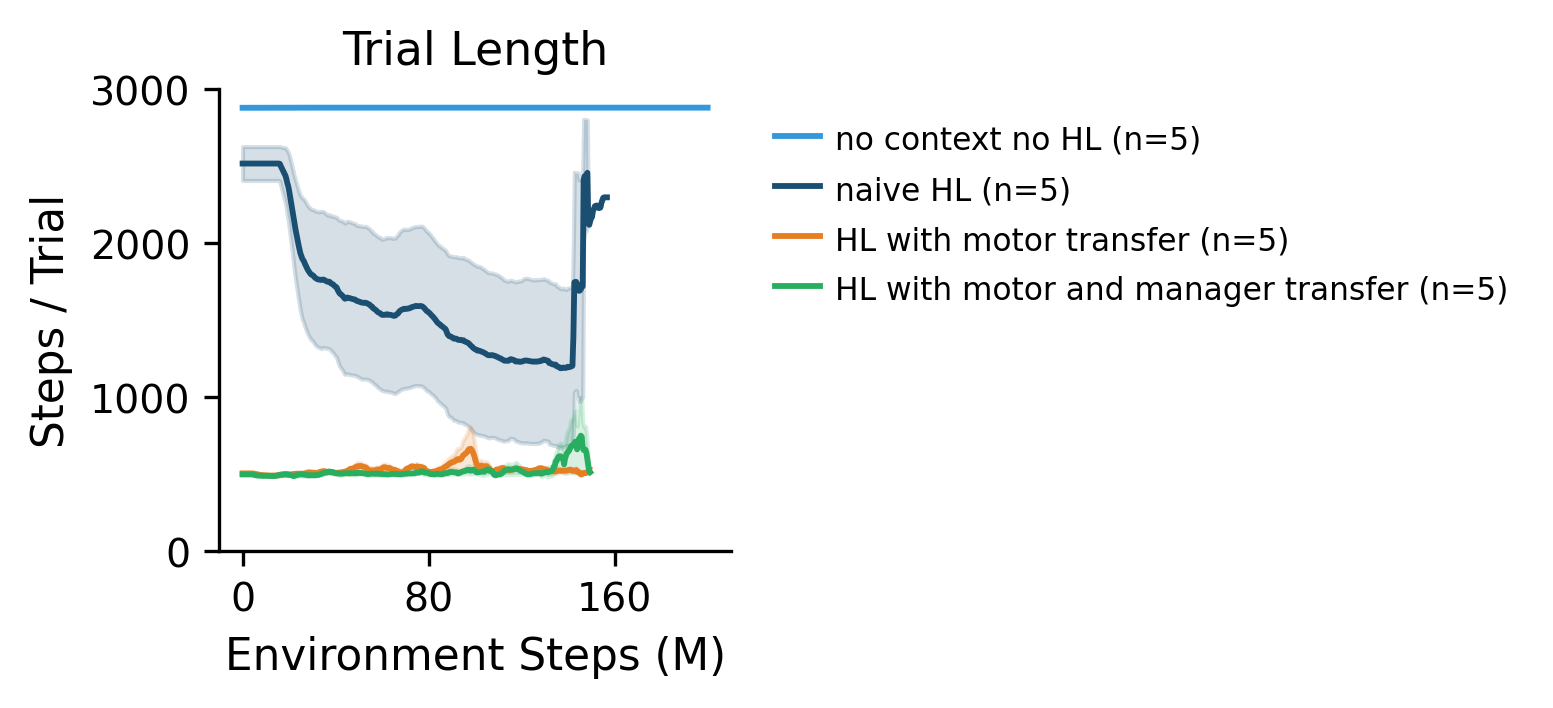

Saved Trial Length figure to trial_length_comparison.pdf and .png


In [42]:
step_axis_millions = target_steps / 1e6
active_setups = [k for k in results if not k.startswith("_")]
import matplotlib.pyplot as plt
# ------------------------------------------------------------------------------
# TRIAL LENGTH PLOT (Individual Standalone Figure)
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(2.2, 2), dpi=300)

for idx, setup_label in enumerate(active_setups):
    data = results[setup_label]
    if data.get("tl_avg") is None or data.get("tl_sem") is None:
        continue

    col = CONDITION_COLORS.get(setup_label, FALLBACK_COLORS[idx % len(FALLBACK_COLORS)])
    n = data.get("n_seeds_tl", data.get("n_seeds", 0))
    label_text = format_compact_label(setup_label, n)

    ax.plot(step_axis_millions, data["tl_avg"], color=col, label=label_text)
    ax.fill_between(
        step_axis_millions,
        np.clip(data["tl_avg"] - data["tl_sem"], 0, None),
        data["tl_avg"] + data["tl_sem"],
        color=col,
        alpha=0.18,
    )

ax.set_title("Trial Length", fontsize=11, pad=6)
ax.set_ylabel("Steps / Trial", fontsize=10.5)
ax.set_xlabel("Environment Steps (M)", fontsize=10.5)
ax.set_ylim(0, 3000)
ax.set_yticks([0, 1000, 2000, 3000])
ax.xaxis.set_major_locator(MaxNLocator(nbins=3, integer=True))
ax.tick_params(axis="both", labelsize=9.5)

ax.legend(handlelength=1.2, handletextpad=0.4, labelspacing=0.45)
style_axes_and_legend(ax)

plt.savefig("HLRNN_vs_nocontext_trial_length_comparison.pdf", dpi=300)
plt.savefig("HLRNN_vs_nocontext_trial_length_comparison.svg", dpi=300)
plt.show()
print("Saved Trial Length figure to trial_length_comparison.pdf and .png")


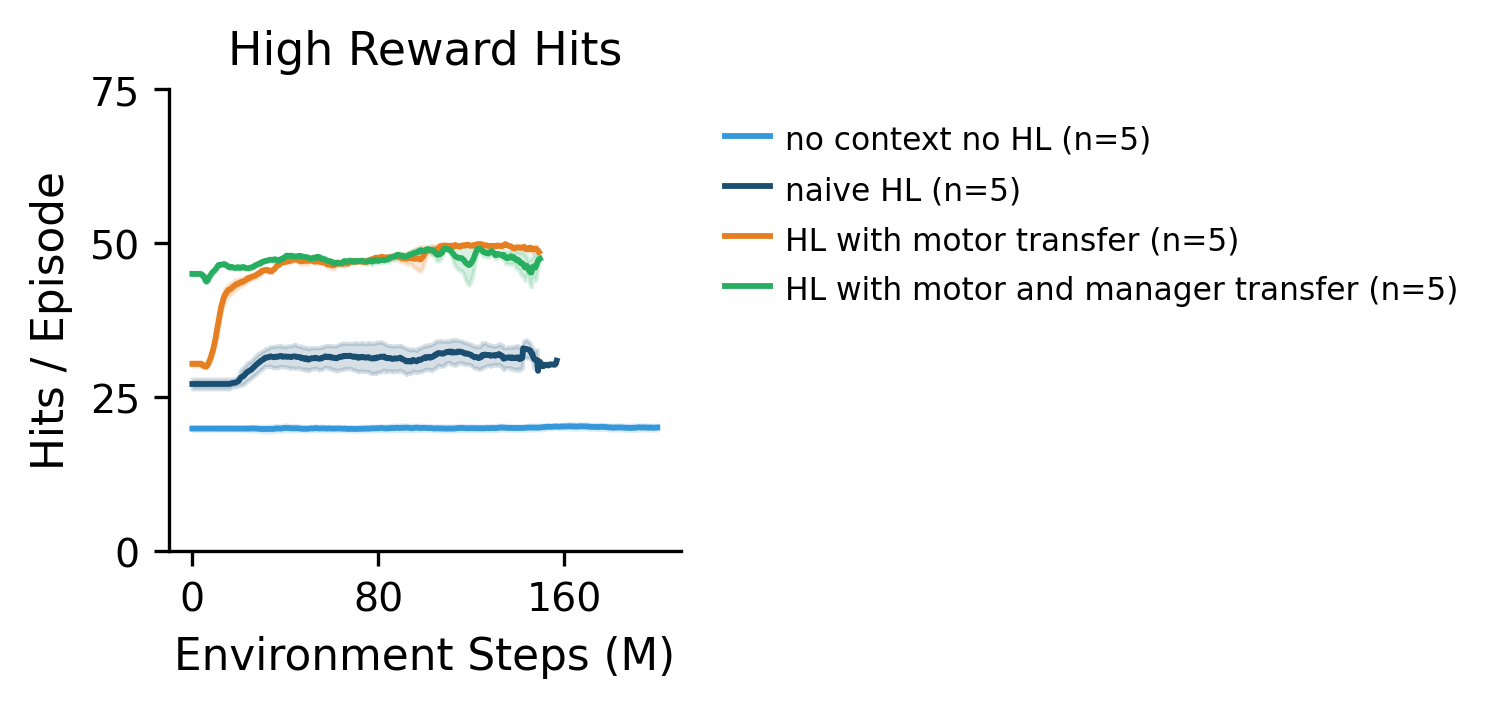

In [43]:
# ------------------------------------------------------------------------------
# HIGH REWARD HITS PLOT
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(2.2, 2), dpi=300)

for idx, setup_label in enumerate(active_setups):
  data = results[setup_label]
  if data.get('highrew_hit_avg') is None:
    continue

  col = CONDITION_COLORS.get(
      setup_label, FALLBACK_COLORS[idx % len(FALLBACK_COLORS)]
  )
  n = data.get('n_seeds_highrew_hit', data.get('n_seeds', 0))
  label_text = format_compact_label(setup_label, n)

  ax.plot(
      step_axis_millions, data['highrew_hit_avg'], color=col, label=label_text
  )
  ax.fill_between(
      step_axis_millions,
      data['highrew_hit_avg'] - data['highrew_hit_sem'],
      data['highrew_hit_avg'] + data['highrew_hit_sem'],
      color=col,
      alpha=0.18,
  )

ax.set_title('High Reward Hits', fontsize=11, pad=6)
ax.set_ylabel('Hits / Episode', fontsize=10.5)
ax.set_xlabel('Environment Steps (M)', fontsize=10.5)
ax.set_ylim(0, 75)
ax.set_yticks([0, 25, 50, 75])
ax.xaxis.set_major_locator(MaxNLocator(nbins=3, integer=True))
ax.tick_params(axis='both', labelsize=9.5)

ax.legend(handlelength=1.2, handletextpad=0.4, labelspacing=0.45)
style_axes_and_legend(ax)


plt.savefig('HLRNN_vs_nocontext_highrew_hit_comparison.pdf', dpi=300)
plt.savefig('HLRNN_vs_nocontext_highrew_hit_comparison.svg', dpi=300)
plt.show()

## 5. Separate Publication Plot: Flexibility (Flexibility Index)

Plots the central **Mean** line with **± SEM** shaded band for flexibility as an individual standalone figure.

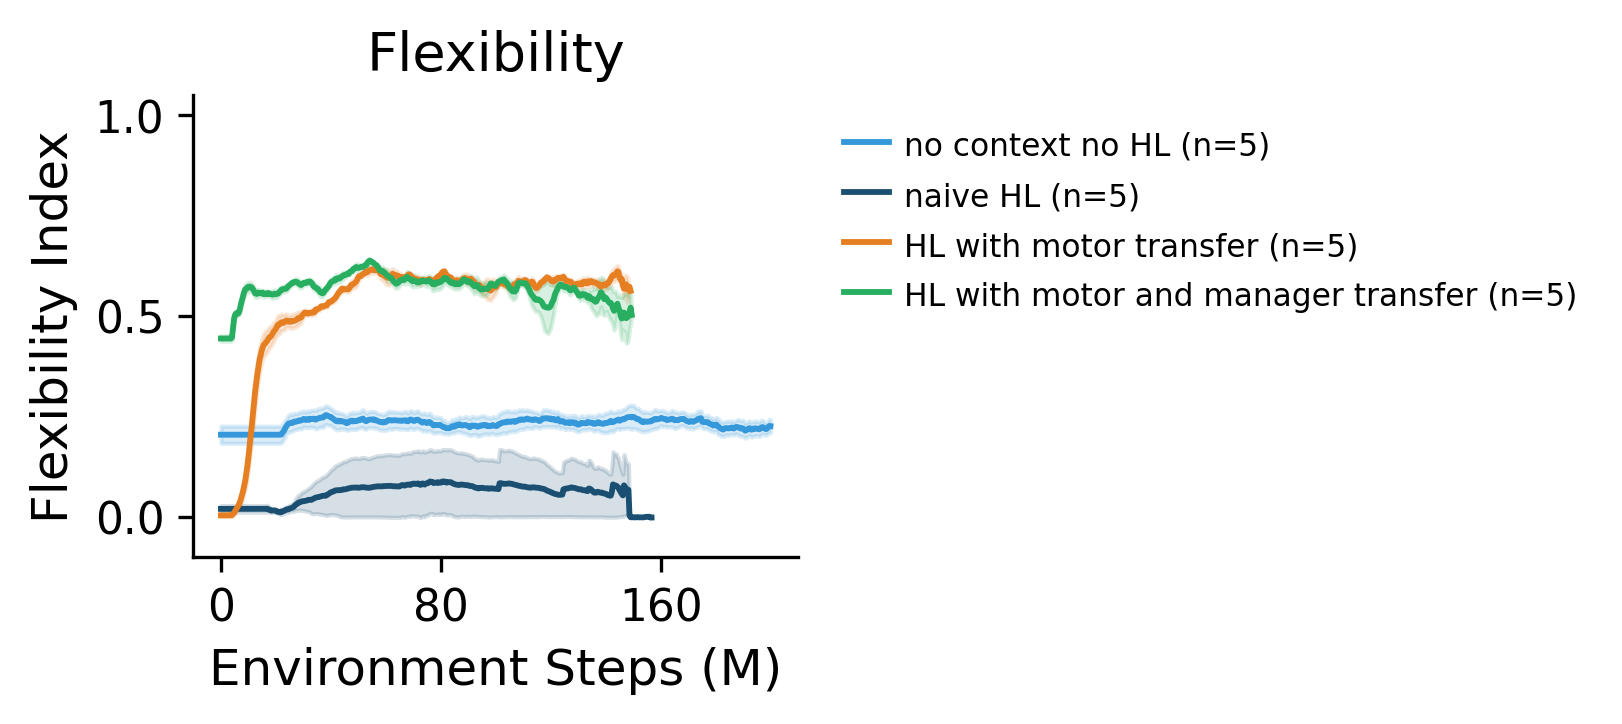

Saved Flexibility figure to flexibility_comparison.pdf and .svg


In [44]:
# ------------------------------------------------------------------------------
# FLEXIBILITY PLOT (Individual Standalone Figure)
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(2.6, 2), dpi=300)

for idx, setup_label in enumerate(active_setups):
    data = results[setup_label]
    if data.get("flex_avg") is None or data.get("flex_sem") is None:
        continue

    col = CONDITION_COLORS.get(setup_label, FALLBACK_COLORS[idx % len(FALLBACK_COLORS)])
    n = data.get("n_seeds_flex", data.get("n_seeds", 0))
    label_text = format_compact_label(setup_label, n)

    ax.plot(step_axis_millions, data["flex_avg"], color=col, label=label_text)
    ax.fill_between(
        step_axis_millions,
        data["flex_avg"] - data["flex_sem"],
        data["flex_avg"] + data["flex_sem"],
        color=col,
        alpha=0.18,
    )

ax.set_title("Flexibility", fontsize=13, pad=6)
ax.set_ylabel("Flexibility Index", fontsize=12)
ax.set_xlabel("Environment Steps (M)", fontsize=12)
ax.set_ylim(-0.1, 1.05)
ax.set_yticks([0, 0.5, 1.0])
ax.xaxis.set_major_locator(MaxNLocator(nbins=3, integer=True))
ax.tick_params(axis="both", labelsize=10.5)

ax.legend(handlelength=1.2, handletextpad=0.4, labelspacing=0.45)
style_axes_and_legend(ax)


plt.savefig("HLRNN_vs_nocontext_flexibility_comparison.pdf", dpi=300)
plt.savefig("HLRNN_vs_nocontext_flexibility_comparison.svg", dpi=300)
plt.show()
print("Saved Flexibility figure to flexibility_comparison.pdf and .svg")


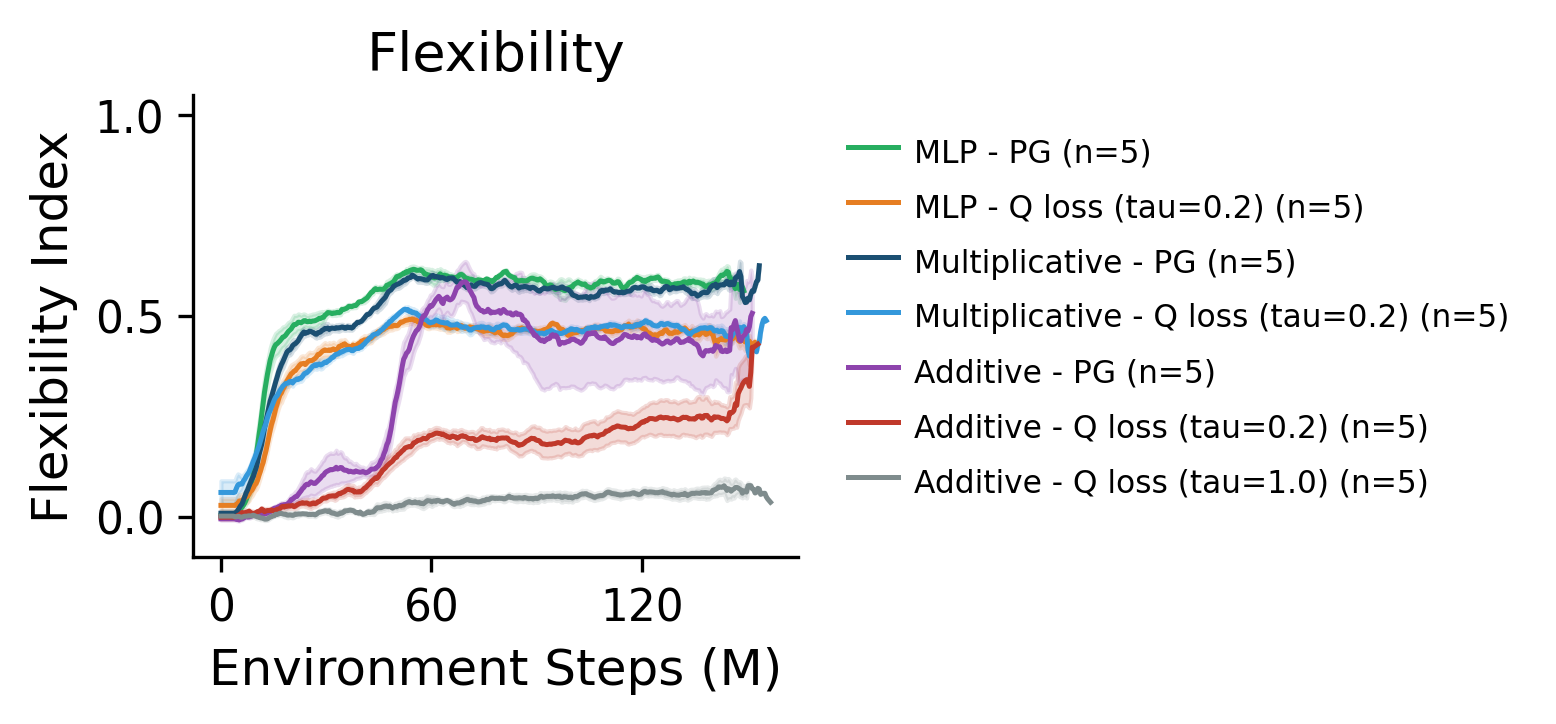

Plotted setups in order:
  1. MLP - PG
  2. MLP - Q loss (tau=0.2)
  3. Multiplicative - PG
  4. Multiplicative - Q loss (tau=0.2)
  5. Policy - PG
  6. NoFreeze - Q loss (tau=0.2)
  7. NoFreeze - Q loss (tau=1.0)


In [14]:
## Flexibility for HL ##
from matplotlib.ticker import MaxNLocator

# ==============================================================================
# 1. 7 DISTINCT COLORS & ORDERING DEFINITION
# ==============================================================================
def get_setup_sort_key(label):
    lbl = label.lower()
    if "nofreeze" in lbl and ("1.0" in lbl or "tau=1" in lbl):
        return 7
    elif "nofreeze" in lbl and "0.2" in lbl:
        return 6
    elif "policy" in lbl:
        return 5
    elif ("multiplicative" in lbl or "multiply" in lbl) and "q" in lbl:
        return 4
    elif ("multiplicative" in lbl or "multiply" in lbl) and "pg" in lbl:
        return 3
    elif "mlp" in lbl and "q" in lbl:
        return 2
    elif "mlp" in lbl and "pg" in lbl:
        return 1
    return 99

def get_setup_color(label):
    lbl = label.lower()
    # 1 & 2: NoFreeze
    if "nofreeze" in lbl and ("1.0" in lbl or "tau=1" in lbl):
        return "#7f8c8d"  # Slate Gray
    if "nofreeze" in lbl and "0.2" in lbl:
        return "#c0392b"  # Crimson Red
    # 3: Policy
    if "policy" in lbl:
        return "#8e44ad"  # Deep Purple
    # 4 & 5: Multiplicative (paired Blues)
    if "multiplicative" in lbl or "multiply" in lbl:
        if "q" in lbl:
            return "#3498db"  # Sky Blue (Q loss)
        if "pg" in lbl:
            return "#1b4f72"  # Deep Navy (PG)
    # 6 & 7: MLP (Orange / Green)
    if "mlp" in lbl:
        if "q" in lbl:
            return "#e67e22"  # Amber Orange (Q loss)
        if "pg" in lbl:
            return "#27ae60"  # Forest Green (PG)
    return "#34495e"

# Sort active setups strictly by your desired 1 -> 7 order
active_setups = [k for k in results if not k.startswith("_")]
active_setups = sorted(active_setups, key=get_setup_sort_key)

# ==============================================================================
# 2. FLEXIBILITY PLOT (Individual Standalone Figure)
# ==============================================================================
fig, ax = plt.subplots(figsize=(2.6, 2), dpi=300)

for idx, setup_label in enumerate(active_setups):
    data = results[setup_label]
    if data.get("flex_avg") is None or data.get("flex_sem") is None:
        continue

    col = get_setup_color(setup_label)
    n = data.get("n_seeds_flex", data.get("n_seeds", 0))
    display_name = setup_label.replace("NoFreeze", "Additive").replace("Policy", "Additive")
    label_text = format_compact_label(display_name, n) if 'format_compact_label' in globals() else f"{display_name} (n={n})"

    ax.plot(step_axis_millions, data["flex_avg"], color=col, lw=1.2, label=label_text)
    ax.fill_between(
        step_axis_millions,
        data["flex_avg"] - data["flex_sem"],
        data["flex_avg"] + data["flex_sem"],
        color=col,
        alpha=0.18,
    )

ax.set_title("Flexibility", fontsize=13, pad=6)
ax.set_ylabel("Flexibility Index", fontsize=12)
ax.set_xlabel("Environment Steps (M)", fontsize=12)
ax.set_ylim(-0.1, 1.05)
ax.set_yticks([0, 0.5, 1.0])
ax.xaxis.set_major_locator(MaxNLocator(nbins=3, integer=True))
ax.tick_params(axis="both", labelsize=10.5)

ax.legend(handlelength=1.2, handletextpad=0.4, labelspacing=0.45)
if 'style_axes_and_legend' in globals():
    style_axes_and_legend(ax)

plt.savefig("flexibility_comparison_hl_oracletransfer.pdf", dpi=300, bbox_inches="tight")
plt.savefig("flexibility_comparison_hl_oracletransfer.svg", dpi=300, bbox_inches="tight")
plt.show()
print("Plotted setups in order:")
for i, s in enumerate(active_setups, 1):
    print(f"  {i}. {s}")

In [ ]:
import os
import pickle
import matplotlib as mpl
from matplotlib.ticker import MaxNLocator
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import wandb

# ==============================================================================
# 1. PUBLICATION SETTINGS & LINEAGE PALETTE
# ==============================================================================
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
mpl.rcParams['font.size'] = 9
mpl.rcParams['lines.linewidth'] = 1.2
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']
mpl.rcParams['savefig.transparent'] = True
mpl.rcParams['savefig.bbox'] = 'tight'

# Lineage-based color mapping:
# 03 Lineage: Blue parent -> Red child
# 05 Lineage: Slate/Teal parent -> Green child
CONDITION_COLORS = {
    'Only R (Run 03)': '#1f77b4',  # Deep Blue
    'Only L (Transfer 03)': '#d62728',  # Red
    'Only R (Run 05)': '#17becf',  # Teal / Slate
    'Only L (Transfer 05)': '#2ca02c',  # Green
}

FALLBACK_COLORS = ['#ff7f0e', '#9467bd', '#8c564b', '#7f7f7f']


def format_compact_label(label: str, n: int) -> str:
  return f'{label} (n={n})'


def style_axes_and_legend(
    ax, legend_loc='upper left', bbox_to_anchor=(1.02, 1.0)
):
  ax.axes.spines[['top', 'right']].set_visible(False)
  legend = ax.get_legend()
  if legend:
    legend.set_frame_on(False)
    legend.set_bbox_to_anchor(bbox_to_anchor)
    legend.set_loc(legend_loc)


# ==============================================================================
# 2. CONFIGURATION
# ==============================================================================
WANDB_ENTITY = 'xiaoxionglin-bernstein-center-freiburg'
PROJECT_HLRNN_CURRICULUM = 'ymaze_HighLevelRNN_curriculum'

NUM_POLICIES = 4
TRIALS_PER_EPISODE = 75
FRAME_SKIP = 4
PER_AGENT_STEP = True  # True: len / (75 * 4) -> agent decision steps

NUM_RESAMPLE_POINTS = 500
MAX_STEP = 200e6

CACHE_FILE = 'cache_hlrnn_curriculum_lineages.pkl' # now named RtoL
FORCE_REFETCH = True


# ==============================================================================
# 3. LINEAGE RUN CLASSIFIER
# ==============================================================================
def classify_run_lineage(run):
  name_lower = run.name.lower()
  exp_lower = str(run.config.get('experiment', '')).lower()
  seed_str = str(run.config.get('seed', '')).strip()
  blob = f'{name_lower} {exp_lower}'

  tokens = (
      blob.replace('=', '_').replace('-', '_').replace('.', '_').split('_')
  )

  # --- ONLY R (filter to 03 and 05; exclude additive/mlp) ---
  if 'onlyr' in blob or 'only_r' in blob or 'only-r' in blob:
    if 'additive' in blob or 'mlp' in blob:
      return None

    is_03 = (
        seed_str in ('3', '03')
        or '03' in tokens
        or 'run03' in blob
        or 'seed03' in blob
        or 'seed3' in blob
        or 'transfer_03' in blob
    )
    is_05 = (
        seed_str in ('5', '05')
        or '05' in tokens
        or 'run05' in blob
        or 'seed05' in blob
        or 'seed5' in blob
        or 'transfer_05' in blob
    )

    if is_03:
      return 'Only R (Run 03)'
    elif is_05:
      return 'Only R (Run 05)'
    else:
      return None  # Disregard other Only R runs

  # --- ONLY L (group by transfer source) ---
  if 'onlyl' in blob or 'only_l' in blob or 'only-l' in blob:
    if (
        'transfer_05' in blob
        or 'transfer_0.5' in blob
        or 'transfer05' in blob
        or 'transfer_5' in blob
    ):
      return 'Only L (Transfer 05)'
    elif (
        'transfer_03' in blob
        or 'transfer_0.3' in blob
        or 'transfer03' in blob
        or 'transfer_3' in blob
    ):
      return 'Only L (Transfer 03)'
    else:
      return None  # Only compare the inherited lineages

  return None


# ==============================================================================
# 4. EXTRACTION & AGGREGATION
# ==============================================================================
def resample_series(df, step_col, metric_col, target_steps):
  clean = df[[step_col, metric_col]].dropna().sort_values(step_col)
  clean = clean.drop_duplicates(subset=step_col, keep='last')
  if len(clean) < 2 or clean[step_col].nunique() < 2:
    return None
  max_step = clean[step_col].max()
  interp_vals = np.interp(
      target_steps, clean[step_col].values, clean[metric_col].values
  )
  interp_vals[target_steps > max_step] = np.nan
  return interp_vals


def fetch_metric_resampled(run, candidate_keys, step_col, target_steps):
  for key in candidate_keys:
    try:
      hist = run.history(keys=[key, step_col], samples=1500, pandas=True)
      if not hist.empty and key in hist.columns and step_col in hist.columns:
        resampled = resample_series(hist, step_col, key, target_steps)
        if resampled is not None:
          return resampled
    except Exception:
      pass
  return None


def fetch_policy_averages_for_seed(
    run,
    target_steps,
    num_policies=NUM_POLICIES,
    trials_per_ep=TRIALS_PER_EPISODE,
    frame_skip=FRAME_SKIP,
    per_agent_step=PER_AGENT_STEP,
):
  policy_tl = []
  policy_hi_hit = []
  policy_lo_miss = []
  tl_divisor = trials_per_ep * frame_skip if per_agent_step else trials_per_ep

  for p in range(num_policies):
    step_col = f'{p}/global_step'
    len_col = f'{p}/len/len'

    # Trial Length
    try:
      hist_tl = run.history(
          keys=[len_col, step_col], samples=1500, pandas=True
      )
      if (
          not hist_tl.empty
          and len_col in hist_tl.columns
          and step_col in hist_tl.columns
      ):
        hist_tl[f'{p}/trial_len'] = hist_tl[len_col] / tl_divisor
        tl_interp = resample_series(
            hist_tl, step_col, f'{p}/trial_len', target_steps
        )
        if tl_interp is not None:
          policy_tl.append(tl_interp)
    except Exception:
      pass

    # Hits / Misses
    hi_interp = fetch_metric_resampled(
        run,
        [f'{p}/custom/highrew_hit', f'{p}/highrew_hit'],
        step_col,
        target_steps,
    )
    if hi_interp is not None:
      policy_hi_hit.append(hi_interp)

    lo_interp = fetch_metric_resampled(
        run,
        [f'{p}/custom/lowrew_miss', f'{p}/lowrew_miss'],
        step_col,
        target_steps,
    )
    if lo_interp is not None:
      policy_lo_miss.append(lo_interp)

  return {
      'tl': np.nanmean(policy_tl, axis=0) if len(policy_tl) > 0 else None,
      'highrew_hit': (
          np.nanmean(policy_hi_hit, axis=0) if len(policy_hi_hit) > 0 else None
      ),
      'lowrew_miss': (
          np.nanmean(policy_lo_miss, axis=0)
          if len(policy_lo_miss) > 0
          else None
      ),
  }


def aggregate_metric(seeds_list):
  if not seeds_list:
    return None, None, None, 0
  seeds_arr = np.array(seeds_list)
  n = len(seeds_list)
  valid_n = np.sum(~np.isnan(seeds_arr), axis=0)
  avg = np.nanmean(seeds_arr, axis=0)
  var = np.nanvar(seeds_arr, axis=0, ddof=1) if n > 1 else np.zeros_like(avg)
  sem = np.where(
      valid_n > 1, np.sqrt(var) / np.sqrt(valid_n), np.zeros_like(var)
  )
  return seeds_arr, avg, sem, n


if not FORCE_REFETCH and os.path.exists(CACHE_FILE):
  print(f'Loading cached data from {CACHE_FILE}...')
  with open(CACHE_FILE, 'rb') as f:
    results = pickle.load(f)
  target_steps = results['_target_steps']
else:
  api = wandb.Api(timeout=60)
  full_proj_path = f'{WANDB_ENTITY}/{PROJECT_HLRNN_CURRICULUM}'
  target_steps = np.linspace(0, MAX_STEP, NUM_RESAMPLE_POINTS)
  results = {'_target_steps': target_steps}

  print(f'Fetching runs from {full_proj_path}...')
  all_runs = list(api.runs(full_proj_path))

  grouped_runs = {}
  for r in all_runs:
    grp = classify_run_lineage(r)
    if grp is not None:
      grouped_runs.setdefault(grp, []).append(r)

  print(f'\nDiscovered lineage groups:')
  for grp, runs_in_grp in sorted(grouped_runs.items()):
    print(f'  • {grp:<28} ({len(runs_in_grp)} runs)')

  for setup_label, matched_runs in sorted(grouped_runs.items()):
    print(f'\n=== Processing: {setup_label} ===')
    seed_tl_list, seed_hi_list, seed_lo_list = [], [], []

    for r in matched_runs:
      seed_val = r.config.get('seed', 'unknown')
      print(f'  - {r.name} (seed={seed_val})')
      seed_res = fetch_policy_averages_for_seed(r, target_steps)
      if seed_res['tl'] is not None:
        seed_tl_list.append(seed_res['tl'])
      if seed_res['highrew_hit'] is not None:
        seed_hi_list.append(seed_res['highrew_hit'])
      if seed_res['lowrew_miss'] is not None:
        seed_lo_list.append(seed_res['lowrew_miss'])

    seeds_tl, tl_avg, tl_sem, n_tl = aggregate_metric(seed_tl_list)
    seeds_hi, hi_avg, hi_sem, n_hi = aggregate_metric(seed_hi_list)
    seeds_lo, lo_avg, lo_sem, n_lo = aggregate_metric(seed_lo_list)

    results[setup_label] = {
        'n_seeds': max(n_tl, n_hi, n_lo),
        'n_seeds_tl': n_tl,
        'seeds_tl': seeds_tl,
        'tl_avg': tl_avg,
        'tl_sem': tl_sem,
        'n_seeds_highrew_hit': n_hi,
        'seeds_highrew_hit': seeds_hi,
        'highrew_hit_avg': hi_avg,
        'highrew_hit_sem': hi_sem,
        'n_seeds_lowrew_miss': n_lo,
        'seeds_lowrew_miss': seeds_lo,
        'lowrew_miss_avg': lo_avg,
        'lowrew_miss_sem': lo_sem,
    }

  with open(CACHE_FILE, 'wb') as f:
    pickle.dump(results, f)
  print(f'\nLineage data saved to {CACHE_FILE}.')

Fetching runs from xiaoxionglin-bernstein-center-freiburg/ymaze_HighLevelRNN_curriculum...

Discovered lineage groups:
  • Only L (Transfer 03)         (5 runs)
  • Only L (Transfer 05)         (5 runs)
  • Only R (Run 03)              (1 runs)
  • Only R (Run 05)              (1 runs)

=== Processing: Only L (Transfer 03) ===
  - 00_2_onlyL_transfer_03_Q_see_1111_20261102_143357_765024 (seed=1111)


/tmp/ipykernel_3419676/4255670057.py:217: RuntimeWarning: Mean of empty slice
  'tl': np.nanmean(policy_tl, axis=0) if len(policy_tl) > 0 else None,
/tmp/ipykernel_3419676/4255670057.py:219: RuntimeWarning: Mean of empty slice
  np.nanmean(policy_hi_hit, axis=0) if len(policy_hi_hit) > 0 else None
/tmp/ipykernel_3419676/4255670057.py:222: RuntimeWarning: Mean of empty slice
  np.nanmean(policy_lo_miss, axis=0)


  - 01_2_onlyL_transfer_03_Q_see_2222_20261102_143357_764884 (seed=2222)


/tmp/ipykernel_3419676/4255670057.py:217: RuntimeWarning: Mean of empty slice
  'tl': np.nanmean(policy_tl, axis=0) if len(policy_tl) > 0 else None,
/tmp/ipykernel_3419676/4255670057.py:219: RuntimeWarning: Mean of empty slice
  np.nanmean(policy_hi_hit, axis=0) if len(policy_hi_hit) > 0 else None
/tmp/ipykernel_3419676/4255670057.py:222: RuntimeWarning: Mean of empty slice
  np.nanmean(policy_lo_miss, axis=0)


  - 02_2_onlyL_transfer_03_Q_see_3333_20261102_143357_769187 (seed=3333)


/tmp/ipykernel_3419676/4255670057.py:217: RuntimeWarning: Mean of empty slice
  'tl': np.nanmean(policy_tl, axis=0) if len(policy_tl) > 0 else None,
/tmp/ipykernel_3419676/4255670057.py:219: RuntimeWarning: Mean of empty slice
  np.nanmean(policy_hi_hit, axis=0) if len(policy_hi_hit) > 0 else None
/tmp/ipykernel_3419676/4255670057.py:222: RuntimeWarning: Mean of empty slice
  np.nanmean(policy_lo_miss, axis=0)


... (14 outputs left out)


=== Processing: Only R (Run 03) ===
  - 03_1_onlyR_see_2222_h.i.pol_False_20261030_155045_538413 (seed=2222)


/tmp/ipykernel_3419676/4255670057.py:217: RuntimeWarning: Mean of empty slice
  'tl': np.nanmean(policy_tl, axis=0) if len(policy_tl) > 0 else None,
/tmp/ipykernel_3419676/4255670057.py:219: RuntimeWarning: Mean of empty slice
  np.nanmean(policy_hi_hit, axis=0) if len(policy_hi_hit) > 0 else None
/tmp/ipykernel_3419676/4255670057.py:222: RuntimeWarning: Mean of empty slice
  np.nanmean(policy_lo_miss, axis=0)
/tmp/ipykernel_3419676/4255670057.py:235: RuntimeWarning: Mean of empty slice
  avg = np.nanmean(seeds_arr, axis=0)
/tmp/ipykernel_3419676/4255670057.py:238: RuntimeWarning: invalid value encountered in divide
  valid_n > 1, np.sqrt(var) / np.sqrt(valid_n), np.zeros_like(var)



=== Processing: Only R (Run 05) ===
  - 05_1_onlyR_see_3333_h.i.pol_False_20261030_155045_538527 (seed=3333)

Lineage data saved to cache_hlrnn_curriculum_lineages.pkl.


/tmp/ipykernel_3419676/4255670057.py:217: RuntimeWarning: Mean of empty slice
  'tl': np.nanmean(policy_tl, axis=0) if len(policy_tl) > 0 else None,
/tmp/ipykernel_3419676/4255670057.py:219: RuntimeWarning: Mean of empty slice
  np.nanmean(policy_hi_hit, axis=0) if len(policy_hi_hit) > 0 else None
/tmp/ipykernel_3419676/4255670057.py:222: RuntimeWarning: Mean of empty slice
  np.nanmean(policy_lo_miss, axis=0)
/tmp/ipykernel_3419676/4255670057.py:235: RuntimeWarning: Mean of empty slice
  avg = np.nanmean(seeds_arr, axis=0)
/tmp/ipykernel_3419676/4255670057.py:238: RuntimeWarning: invalid value encountered in divide
  valid_n > 1, np.sqrt(var) / np.sqrt(valid_n), np.zeros_like(var)


In [19]:
print(os.path.abspath("curriculum_onlytransfers_highrew_hit_comparison.pdf"))

/work/classic/fr_ze12-data2/curriculum_onlytransfers_highrew_hit_comparison.pdf


## 6. Detailed Diagnostics: Individual Seed Traces & SEM Curves

Inspect individual seed curves (faint traces) and exact SEM trajectories over training steps.

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(6.5, 4.0), dpi=300, sharex=True)

for idx, setup_label in enumerate(active_setups):
    data = results[setup_label]
    col = CONDITION_COLORS.get(setup_label, FALLBACK_COLORS[idx % len(FALLBACK_COLORS)])
    n_tl = data.get("n_seeds_tl", data.get("n_seeds", 0))
    n_flex = data.get("n_seeds_flex", data.get("n_seeds", 0))

    # Row 0, Col 0: Trial Length Mean + Seeds
    if data.get("tl_avg") is not None:
        axes[0, 0].plot(step_axis_millions, data["tl_avg"], color=col, label=f"{setup_label} (n={n_tl})")
        if data.get("seeds_tl") is not None:
            for s in range(len(data["seeds_tl"])):
                axes[0, 0].plot(step_axis_millions, data["seeds_tl"][s], color=col, alpha=0.18, linewidth=0.7)

    # Row 0, Col 1: Flexibility Mean + Seeds
    if data.get("flex_avg") is not None:
        axes[0, 1].plot(step_axis_millions, data["flex_avg"], color=col, label=f"{setup_label} (n={n_flex})")
        if data.get("seeds_flex") is not None:
            for s in range(len(data["seeds_flex"])):
                axes[0, 1].plot(step_axis_millions, data["seeds_flex"][s], color=col, alpha=0.18, linewidth=0.7)

    # Row 1, Col 0: Trial Length SEM
    if data.get("tl_sem") is not None:
        axes[1, 0].plot(step_axis_millions, data["tl_sem"], color=col, label=setup_label)

    # Row 1, Col 1: Flexibility SEM
    if data.get("flex_sem") is not None:
        axes[1, 1].plot(step_axis_millions, data["flex_sem"], color=col, label=setup_label)

axes[0, 0].set_title("Trial Length (Steps / Trial)", pad=4)
axes[0, 0].set_ylabel("Steps / Trial")
axes[0, 0].set_ylim(0, 3000)
axes[0, 0].legend()
style_axes_and_legend(axes[0, 0], bbox_to_anchor=(1.02, 1))

axes[0, 1].set_title("Flexibility", pad=4)
axes[0, 1].set_ylabel("Flexibility Index")
axes[0, 1].legend()
style_axes_and_legend(axes[0, 1], bbox_to_anchor=(1.02, 1))

axes[1, 0].set_title("Trial Length SEM", pad=4)
axes[1, 0].set_ylabel("SEM (Steps)")
axes[1, 0].set_xlabel("Environment Steps (M)")
axes[1, 0].legend()
style_axes_and_legend(axes[1, 0], bbox_to_anchor=(1.02, 1))

axes[1, 1].set_title("Flexibility SEM", pad=4)
axes[1, 1].set_ylabel("SEM")
axes[1, 1].set_xlabel("Environment Steps (M)")
axes[1, 1].legend()
style_axes_and_legend(axes[1, 1], bbox_to_anchor=(1.02, 1))

plt.savefig("breakdown_averages_and_sem.pdf", dpi=300)
plt.savefig("breakdown_averages_and_sem.png", dpi=300)
plt.show()
print("Saved breakdown diagnostics to breakdown_averages_and_sem.pdf and .png")
